# Head specialization: does each induction head serve particular transitions?

**Question.** Switching off the top induction heads together cut in-context grammar learning sharply
(`03_induction_heads`). Do the heads share the work evenly (interchangeable copies of one mechanism), or does each
head serve **particular transitions** of the grammar, so that switching off one head makes the model fail exactly on
those transitions?

A head cannot store a specific word pair: the weights are frozen and every run uses different random words. What a
head *can* do is specialize in a **kind** of transition, e.g. the ones that simple copying solves versus the ones that
need more context.

**Plan.**
1. **Part 1:** the top-16 heads switched off together, broken down per transition. Does the switch-off hit the
   ambiguous transitions harder? It first tries the saved results of `03_induction_heads` (no new runs); if they do
   not match this session's word streams, it runs no switch-off, top 16 and 16 random heads fresh (about 25 min).
2. **Step A (about 15 min):** an attention map. For each head and each transition, how much does the head attend to
   the correct earlier continuation?
3. **Step B (about 1.5 h):** switch off one head at a time (the top 12 heads, plus block 12 head 6, plus 2 random
   control heads) and measure the change at every transition, paired run by run against no switch-off.
4. **Step C (only if the single-head effects are tiny, about 2 h):** switch off all top-16 heads *except one*, for each
   of them. What does each head restore on its own, transition by transition?

**Run 2 settings (default):** Step B already ran in run 1 (`head_specialization_run1_executed.ipynb`), so it is
switched off (`RUN_STEP_B = False`), and Step C is switched on (`LEAVE_ONE_IN = True`): about 2.4 hours in total.

**Run order (Colab T4, 8-bit model).** Run all cells top to bottom.
Steps A–C save everything to Drive as they go; after a disconnect: reconnect, **Runtime → Run all**, approve the
Drive popup, and finished parts load in seconds.

In [1]:
# Stop right away if there is no GPU (NVIDIA in Colab, or an Apple Silicon Mac): on CPU the 7B model does not
# fit in memory and loading stalls.
import os
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')  # less memory fragmentation
import torch
REQUIRE_GPU = True
if torch.cuda.is_available():
  print(f"GPU: {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
  print("GPU: Apple Silicon (MPS); the model runs in float16 (8-bit loading needs an NVIDIA GPU)")
elif REQUIRE_GPU:
  raise RuntimeError("No GPU. In Colab: Runtime -> Change runtime type -> T4 GPU -> Save, then Runtime -> Run all. "
                     "If Colab says no GPU is available, its free GPU quota is used up for now: try again later.")

# Google Drive first: Colab asks for permission once per new runtime. Approve the popup right away;
# "Run all" waits here until you do. Everything slow (tuned lens, lens results) is saved there.
USE_GOOGLE_DRIVE = True
DRIVE_CACHE_DIR = '/content/drive/MyDrive/plasticity_lens_cache'
if USE_GOOGLE_DRIVE:
  try:
    from google.colab import drive
    drive.mount('/content/drive')
  except ImportError:
    print("not running in Colab; results are saved locally")

!pip install -q -U bitsandbytes
!pip install -q datasets  # tuned-lens training text


GPU: Tesla T4
Mounted at /content/drive


## Import packages

In [2]:
import json
import random
from tqdm import tqdm
random.seed(42)

## Set run parameters

In [3]:
RANDOM_WEIGHTS = False  # set to True if you want to use an untrained network
NO_REPETITIONS = False # set to False if you don't care about repetitions
model_name = 'mistral'  # paper's primary model (Mistral-7B-v0.3); use 'llama' for SI Fig. S3/S4A, 'gpt2' for SI Fig. S12
LOAD_IN_8BIT_ON_CUDA = True  # set False if your GPU has enough memory for full float16 (e.g. A100/L4); needed on a free-tier T4 (14.5GB) to avoid OOM
SEP_TOKEN = 'END'
iterations = 100
random_epochs = 85
learning_epochs = 340
END_NODE_ID = "END"
tokens_type = "words" # "words" "letters" "digits" "symbols" "all_nouns" "all_verbs"

In [4]:
def extract_subset(word_list):
    """Extracts only noun words or verbs from a list using spaCy."""
    if tokens_type == "all_nouns":
      pos = "NOUN"
    elif tokens_type == "all_verbs":
      pos = "VERB"
    print(f"extracting {pos}")
    import spacy  # only needed for tokens_type "all_nouns"/"all_verbs" (requires en_core_web_trf)
    nlp = spacy.load("en_core_web_trf")  # Load spaCy's English model
    tokens = nlp(" ".join(word_list))
    reduced = [token.text for token in nlp(" ".join(word_list)) if token.pos_ == pos]
    return reduced

In [5]:
if tokens_type == "letters":
  tokens_list = list('abcdefghijklmnopqrstuvwxyz')
elif tokens_type == "digits":
  tokens_list = list('123456789')
  SEP_TOKEN = "000"
elif tokens_type == "symbols":
  tokens_list = list('!@#$%^&*()_+-={}[]±§/\"\':;.?>,<~`´')
  SEP_TOKEN = "|"
  assert SEP_TOKEN not in tokens_list
elif tokens_type == "words" or tokens_type == "all_nouns" or tokens_type == "all_verbs":
  tokens_list = ['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'airport', 'album', 'alcohol', 'alive', 'all', 'alliance', 'allow', 'ally', 'almost', 'alone', 'along', 'already', 'also', 'alter', 'alternative', 'although', 'always', 'AM', 'amazing', 'American', 'among', 'amount', 'analysis', 'analyst', 'analyze', 'ancient', 'and', 'anger', 'angle', 'angry', 'animal', 'anniversary', 'announce', 'annual', 'another', 'answer', 'anticipate', 'anxiety', 'any', 'anybody', 'anymore', 'anyone', 'anything', 'anyway', 'anywhere', 'apart', 'apartment', 'apparent', 'apparently', 'appeal', 'appear', 'appearance', 'apple', 'application', 'apply', 'appoint', 'appointment', 'appreciate', 'approach', 'appropriate', 'approval', 'approve', 'approximately', 'Arab', 'architect', 'area', 'argue', 'argument', 'arise', 'arm', 'armed', 'army', 'around', 'arrange', 'arrangement', 'arrest', 'arrival', 'arrive', 'art', 'article', 'artist', 'artistic', 'as', 'Asian', 'aside', 'ask', 'asleep', 'aspect', 'assault', 'assert', 'assess', 'assessment', 'asset', 'assign', 'assignment', 'assist', 'assistance', 'assistant', 'associate', 'association', 'assume', 'assumption', 'assure', 'at', 'athlete', 'athletic', 'atmosphere', 'attach', 'attack', 'attempt', 'attend', 'attention', 'attitude', 'attorney', 'attract', 'attractive', 'attribute', 'audience', 'author', 'authority', 'auto', 'available', 'average', 'avoid', 'award', 'aware', 'awareness', 'away', 'awful', 'baby', 'back', 'background', 'bad', 'badly', 'bag', 'bake', 'balance', 'ball', 'ban', 'band', 'bank', 'bar', 'barely', 'barrel', 'barrier', 'base', 'baseball', 'basic', 'basically', 'basis', 'basket', 'basketball', 'bathroom', 'battery', 'battle', 'be', 'beach', 'bean', 'bear', 'beat', 'beautiful', 'beauty', 'because', 'become', 'bed', 'bedroom', 'beer', 'before', 'begin', 'beginning', 'behavior', 'behind', 'being', 'belief', 'believe', 'bell', 'belong', 'below', 'belt', 'bench', 'bend', 'beneath', 'benefit', 'beside', 'besides', 'best', 'bet', 'better', 'between', 'beyond', 'Bible', 'big', 'bike', 'bill', 'billion', 'bind', 'biological', 'bird', 'birth', 'birthday', 'bit', 'bite', 'black', 'blade', 'blame', 'blanket', 'blind', 'block', 'blood', 'blow', 'blue', 'board', 'boat', 'body', 'bomb', 'bombing', 'bond', 'bone', 'book', 'boom', 'boot', 'border', 'born', 'borrow', 'boss', 'both', 'bother', 'bottle', 'bottom', 'boundary', 'bowl', 'box', 'boy', 'boyfriend', 'brain', 'branch', 'brand', 'bread', 'break', 'breakfast', 'breast', 'breath', 'breathe', 'brick', 'bridge', 'brief', 'briefly', 'bright', 'brilliant', 'bring', 'British', 'broad', 'broken', 'brother', 'brown', 'brush', 'buck', 'budget', 'build', 'building', 'bullet', 'bunch', 'burden', 'burn', 'bury', 'bus', 'business', 'busy', 'but', 'butter', 'button', 'buy', 'buyer', 'by', 'cabin', 'cabinet', 'cable', 'cake', 'calculate', 'call', 'camera', 'camp', 'campaign', 'campus', 'can', 'Canadian', 'cancer', 'candidate', 'cap', 'capability', 'capable', 'capacity', 'capital', 'captain', 'capture', 'car', 'carbon', 'card', 'care', 'career', 'careful', 'carefully', 'carrier', 'carry', 'case', 'cash', 'cast', 'cat', 'catch', 'category', 'Catholic', 'cause', 'ceiling', 'celebrate', 'celebration', 'celebrity', 'cell', 'center', 'central', 'century', 'CEO', 'ceremony', 'certain', 'certainly', 'chain', 'chair', 'chairman', 'challenge', 'chamber', 'champion', 'championship', 'chance', 'change', 'changing', 'channel', 'chapter', 'character', 'characteristic', 'characterize', 'charge', 'charity', 'chart', 'chase', 'cheap', 'check', 'cheek', 'cheese', 'chef', 'chemical', 'chest', 'chicken', 'chief', 'child', 'childhood', 'Chinese', 'chip', 'chocolate', 'choice', 'cholesterol', 'choose', 'Christian', 'Christmas', 'church', 'cigarette', 'circle', 'circumstance', 'cite', 'citizen', 'city', 'civil', 'civilian', 'claim', 'class', 'classic', 'classroom', 'clean', 'clear', 'clearly', 'client', 'climate', 'climb', 'clinic', 'clinical', 'clock', 'close', 'closely', 'closer', 'clothes', 'clothing', 'cloud', 'club', 'clue', 'cluster', 'coach', 'coal', 'coalition', 'coast', 'coat', 'code', 'coffee', 'cognitive', 'cold', 'collapse', 'colleague', 'collect', 'collection', 'collective', 'college', 'colonial', 'color', 'column', 'combination', 'combine', 'come', 'comedy', 'comfort', 'comfortable', 'command', 'commander', 'comment', 'commercial', 'commission', 'commit', 'commitment', 'committee', 'common', 'communicate', 'communication', 'community', 'company', 'compare', 'comparison', 'compete', 'competition', 'competitive', 'competitor', 'complain', 'complaint', 'complete', 'completely', 'complex', 'complicated', 'component', 'compose', 'composition', 'comprehensive', 'computer', 'concentrate', 'concentration', 'concept', 'concern', 'concerned', 'concert', 'conclude', 'conclusion', 'concrete', 'condition', 'conduct', 'conference', 'confidence', 'confident', 'confirm', 'conflict', 'confront', 'confusion', 'Congress', 'congressional', 'connect', 'connection', 'consciousness', 'consensus', 'consequence', 'conservative', 'consider', 'considerable', 'consideration', 'consist', 'consistent', 'constant', 'constantly', 'constitute', 'constitutional', 'construct', 'construction', 'consultant', 'consume', 'consumer', 'consumption', 'contact', 'contain', 'container', 'contemporary', 'content', 'contest', 'context', 'continue', 'continued', 'contract', 'contrast', 'contribute', 'contribution', 'control', 'controversial', 'controversy', 'convention', 'conventional', 'conversation', 'convert', 'conviction', 'convince', 'cook', 'cookie', 'cooking', 'cool', 'cooperation', 'cop', 'cope', 'copy', 'core', 'corn', 'corner', 'corporate', 'corporation', 'correct', 'correspondent', 'cost', 'cotton', 'couch', 'could', 'council', 'counselor', 'count', 'counter', 'country', 'county', 'couple', 'courage', 'course', 'court', 'cousin', 'cover', 'coverage', 'cow', 'crack', 'craft', 'crash', 'crazy', 'cream', 'create', 'creation', 'creative', 'creature', 'credit', 'crew', 'crime', 'criminal', 'crisis', 'criteria', 'critic', 'critical', 'criticism', 'criticize', 'crop', 'cross', 'crowd', 'crucial', 'cry', 'cultural', 'culture', 'cup', 'curious', 'current', 'currently', 'curriculum', 'custom', 'customer', 'cut', 'cycle', 'dad', 'daily', 'damage', 'dance', 'danger', 'dangerous', 'dare', 'dark', 'darkness', 'data', 'date', 'daughter', 'day', 'dead', 'deal', 'dealer', 'dear', 'death', 'debate', 'debt', 'decade', 'decide', 'decision', 'deck', 'declare', 'decline', 'decrease', 'deep', 'deeply', 'deer', 'defeat', 'defend', 'defendant', 'defense', 'defensive', 'deficit', 'define', 'definitely', 'definition', 'degree', 'delay', 'deliver', 'delivery', 'demand', 'democracy', 'Democrat', 'democratic', 'demonstrate', 'demonstration', 'deny', 'department', 'depend', 'dependent', 'depending', 'depict', 'depression', 'depth', 'deputy', 'derive', 'describe', 'description', 'desert', 'deserve', 'design', 'designer', 'desire', 'desk', 'desperate', 'despite', 'destroy', 'destruction', 'detail', 'detailed', 'detect', 'determine', 'develop', 'developing', 'development', 'device', 'devote', 'dialogue', 'die', 'diet', 'differ', 'difference', 'different', 'differently', 'difficult', 'difficulty', 'dig', 'digital', 'dimension', 'dining', 'dinner', 'direct', 'direction', 'directly', 'director', 'dirt', 'dirty', 'disability', 'disagree', 'disappear', 'disaster', 'discipline', 'discourse', 'discover', 'discovery', 'discrimination', 'discuss', 'discussion', 'disease', 'dish', 'dismiss', 'disorder', 'display', 'dispute', 'distance', 'distant', 'distinct', 'distinction', 'distinguish', 'distribute', 'distribution', 'district', 'diverse', 'diversity', 'divide', 'division', 'divorce', 'DNA', 'do', 'doctor', 'document', 'dog', 'domestic', 'dominant', 'dominate', 'door', 'double', 'doubt', 'down', 'downtown', 'dozen', 'draft', 'drag', 'drama', 'dramatic', 'dramatically', 'draw', 'drawing', 'dream', 'dress', 'drink', 'drive', 'driver', 'drop', 'drug', 'dry', 'due', 'during', 'dust', 'duty', 'each', 'eager', 'ear', 'early', 'earn', 'earnings', 'earth', 'ease', 'easily', 'east', 'eastern', 'easy', 'eat', 'economic', 'economics', 'economist', 'economy', 'edge', 'edition', 'editor', 'educate', 'education', 'educational', 'educator', 'effect', 'effective', 'effectively', 'efficiency', 'efficient', 'effort', 'egg', 'eight', 'either', 'elderly', 'elect', 'election', 'electric', 'electricity', 'electronic', 'element', 'elementary', 'eliminate', 'elite', 'else', 'elsewhere', 'e-mail', 'embrace', 'emerge', 'emergency', 'emission', 'emotion', 'emotional', 'emphasis', 'emphasize', 'employ', 'employee', 'employer', 'employment', 'empty', 'enable', 'encounter', 'encourage', 'enemy', 'energy', 'enforcement', 'engage', 'engine', 'engineer', 'engineering', 'English', 'enhance', 'enjoy', 'enormous', 'enough', 'ensure', 'enter', 'enterprise', 'entertainment', 'entire', 'entirely', 'entrance', 'entry', 'environment', 'environmental', 'episode', 'equal', 'equally', 'equipment', 'era', 'error', 'escape', 'especially', 'essay', 'essential', 'essentially', 'establish', 'establishment', 'estate', 'estimate', 'etc', 'ethics', 'ethnic', 'European', 'evaluate', 'evaluation', 'even', 'evening', 'event', 'eventually', 'ever', 'every', 'everybody', 'everyday', 'everyone', 'everything', 'everywhere', 'evidence', 'evolution', 'evolve', 'exact', 'exactly', 'examination', 'examine', 'example', 'exceed', 'excellent', 'except', 'exception', 'exchange', 'exciting', 'executive', 'exercise', 'exhibit', 'exhibition', 'exist', 'existence', 'existing', 'expand', 'expansion', 'expect', 'expectation', 'expense', 'expensive', 'experience', 'experiment', 'expert', 'explain', 'explanation', 'explode', 'explore', 'explosion', 'expose', 'exposure', 'express', 'expression', 'extend', 'extension', 'extensive', 'extent', 'external', 'extra', 'extraordinary', 'extreme', 'extremely', 'eye', 'fabric', 'face', 'facility', 'fact', 'factor', 'factory', 'faculty', 'fade', 'fail', 'failure', 'fair', 'fairly', 'faith', 'fall', 'false', 'familiar', 'family', 'famous', 'fan', 'fantasy', 'far', 'farm', 'farmer', 'fashion', 'fast', 'fat', 'fate', 'father', 'fault', 'favor', 'favorite', 'fear', 'feature', 'federal', 'fee', 'feed', 'feel', 'feeling', 'fellow', 'female', 'fence', 'few', 'fewer', 'fiber', 'fiction', 'field', 'fifteen', 'fifth', 'fifty', 'fight', 'fighter', 'fighting', 'figure', 'file', 'fill', 'film', 'final', 'finally', 'finance', 'financial', 'find', 'finding', 'fine', 'finger', 'finish', 'fire', 'firm', 'first', 'fish', 'fishing', 'fit', 'fitness', 'five', 'fix', 'flag', 'flame', 'flat', 'flavor', 'flee', 'flesh', 'flight', 'float', 'floor', 'flow', 'flower', 'fly', 'focus', 'folk', 'follow', 'following', 'food', 'foot', 'football', 'for', 'force', 'foreign', 'forest', 'forever', 'forget', 'form', 'formal', 'formation', 'former', 'formula', 'forth', 'fortune', 'forward', 'found', 'foundation', 'founder', 'four', 'fourth', 'frame', 'framework', 'free', 'freedom', 'freeze', 'French', 'frequency', 'frequent', 'frequently', 'fresh', 'friend', 'friendly', 'friendship', 'from', 'front', 'fruit', 'frustration', 'fuel', 'full', 'fully', 'fun', 'function', 'fund', 'fundamental', 'funding', 'funeral', 'funny', 'furniture', 'furthermore', 'future', 'gain', 'galaxy', 'gallery', 'game', 'gang', 'gap', 'garage', 'garden', 'garlic', 'gas', 'gate', 'gather', 'gay', 'gaze', 'gear', 'gender', 'gene', 'general', 'generally', 'generate', 'generation', 'genetic', 'gentleman', 'gently', 'German', 'gesture', 'get', 'ghost', 'giant', 'gift', 'gifted', 'girl', 'girlfriend', 'give', 'given', 'glad', 'glance', 'glass', 'global', 'glove', 'go', 'goal', 'God', 'gold', 'golden', 'golf', 'good', 'government', 'governor', 'grab', 'grade', 'gradually', 'graduate', 'grain', 'grand', 'grandfather', 'grandmother', 'grant', 'grass', 'grave', 'gray', 'great', 'greatest', 'green', 'grocery', 'ground', 'group', 'grow', 'growing', 'growth', 'guarantee', 'guard', 'guess', 'guest', 'guide', 'guideline', 'guilty', 'gun', 'guy', 'habit', 'habitat', 'hair', 'half', 'hall', 'hand', 'handful', 'handle', 'hang', 'happen', 'happy', 'hard', 'hardly', 'hat', 'hate', 'have', 'he', 'head', 'headline', 'headquarters', 'health', 'healthy', 'hear', 'hearing', 'heart', 'heat', 'heaven', 'heavily', 'heavy', 'heel', 'height', 'helicopter', 'hell', 'hello', 'help', 'helpful', 'her', 'here', 'heritage', 'hero', 'herself', 'hey', 'hi', 'hide', 'high', 'highlight', 'highly', 'highway', 'hill', 'him', 'himself', 'hip', 'hire', 'his', 'historian', 'historic', 'historical', 'history', 'hit', 'hold', 'hole', 'holiday', 'holy', 'home', 'homeless', 'honest', 'honey', 'honor', 'hope', 'horizon', 'horror', 'horse', 'hospital', 'host', 'hot', 'hotel', 'hour', 'house', 'household', 'housing', 'how', 'however', 'huge', 'human', 'humor', 'hundred', 'hungry', 'hunter', 'hunting', 'hurt', 'husband', 'hypothesis', 'I', 'ice', 'idea', 'ideal', 'identification', 'identify', 'identity', 'ie', 'if', 'ignore', 'ill', 'illegal', 'illness', 'illustrate', 'image', 'imagination', 'imagine', 'immediate', 'immediately', 'immigrant', 'immigration', 'impact', 'implement', 'implication', 'imply', 'importance', 'important', 'impose', 'impossible', 'impress', 'impression', 'impressive', 'improve', 'improvement', 'in', 'incentive', 'incident', 'include', 'including', 'income', 'incorporate', 'increase', 'increased', 'increasing', 'increasingly', 'incredible', 'indeed', 'independence', 'independent', 'index', 'Indian', 'indicate', 'indication', 'individual', 'industrial', 'industry', 'infant', 'infection', 'inflation', 'influence', 'inform', 'information', 'ingredient', 'initial', 'initially', 'initiative', 'injury', 'inner', 'innocent', 'inquiry', 'inside', 'insight', 'insist', 'inspire', 'install', 'instance', 'instead', 'institution', 'institutional', 'instruction', 'instructor', 'instrument', 'insurance', 'intellectual', 'intelligence', 'intend', 'intense', 'intensity', 'intention', 'interaction', 'interest', 'interested', 'interesting', 'internal', 'international', 'Internet', 'interpret', 'interpretation', 'intervention', 'interview', 'into', 'introduce', 'introduction', 'invasion', 'invest', 'investigate', 'investigation', 'investigator', 'investment', 'investor', 'invite', 'involve', 'involved', 'involvement', 'Iraqi', 'Irish', 'iron', 'Islamic', 'island', 'Israeli', 'issue', 'it', 'Italian', 'item', 'its', 'itself', 'jacket', 'jail', 'Japanese', 'jet', 'Jew', 'Jewish', 'job', 'join', 'joint', 'joke', 'journal', 'journalist', 'journey', 'joy', 'judge', 'judgment', 'juice', 'jump', 'junior', 'jury', 'just', 'justice', 'justify', 'keep', 'key', 'kick', 'kid', 'kill', 'killer', 'killing', 'kind', 'king', 'kiss', 'kitchen', 'knee', 'knife', 'knock', 'know', 'knowledge', 'lab', 'label', 'labor', 'laboratory', 'lack', 'lady', 'lake', 'land', 'landscape', 'language', 'lap', 'large', 'largely', 'last', 'late', 'later', 'Latin', 'latter', 'laugh', 'launch', 'law', 'lawn', 'lawsuit', 'lawyer', 'lay', 'layer', 'lead', 'leader', 'leadership', 'leading', 'leaf', 'league', 'lean', 'learn', 'learning', 'least', 'leather', 'leave', 'left', 'leg', 'legacy', 'legal', 'legend', 'legislation', 'legitimate', 'lemon', 'length', 'less', 'lesson', 'let', 'letter', 'level', 'liberal', 'library', 'license', 'lie', 'life', 'lifestyle', 'lifetime', 'lift', 'light', 'like', 'likely', 'limit', 'limitation', 'limited', 'line', 'link', 'lip', 'list', 'listen', 'literally', 'literary', 'literature', 'little', 'live', 'living', 'load', 'loan', 'local', 'locate', 'location', 'lock', 'long', 'long-term', 'look', 'loose', 'lose', 'loss', 'lost', 'lot', 'lots', 'loud', 'love', 'lovely', 'lover', 'low', 'lower', 'luck', 'lucky', 'lunch', 'lung', 'machine', 'mad', 'magazine', 'mail', 'main', 'mainly', 'maintain', 'maintenance', 'major', 'majority', 'make', 'maker', 'makeup', 'male', 'mall', 'man', 'manage', 'management', 'manager', 'manner', 'manufacturer', 'manufacturing', 'many', 'map', 'margin', 'mark', 'market', 'marketing', 'marriage', 'married', 'marry', 'mask', 'mass', 'massive', 'master', 'match', 'material', 'math', 'matter', 'may', 'maybe', 'mayor', 'me', 'meal', 'mean', 'meaning', 'meanwhile', 'measure', 'measurement', 'meat', 'mechanism', 'media', 'medical', 'medication', 'medicine', 'medium', 'meet', 'meeting', 'member', 'membership', 'memory', 'mental', 'mention', 'menu', 'mere', 'merely', 'mess', 'message', 'metal', 'meter', 'method', 'Mexican', 'middle', 'might', 'military', 'milk', 'million', 'mind', 'mine', 'minister', 'minor', 'minority', 'minute', 'miracle', 'mirror', 'miss', 'missile', 'mission', 'mistake', 'mix', 'mixture', 'mm-hmm', 'mode', 'model', 'moderate', 'modern', 'modest', 'mom', 'moment', 'money', 'monitor', 'month', 'mood', 'moon', 'moral', 'more', 'moreover', 'morning', 'mortgage', 'most', 'mostly', 'mother', 'motion', 'motivation', 'motor', 'mount', 'mountain', 'mouse', 'mouth', 'move', 'movement', 'movie', 'Mr', 'Mrs', 'Ms', 'much', 'multiple', 'murder', 'muscle', 'museum', 'music', 'musical', 'musician', 'Muslim', 'must', 'mutual', 'my', 'myself', 'mystery', 'myth', 'naked', 'name', 'narrative', 'narrow', 'nation', 'national', 'native', 'natural', 'naturally', 'nature', 'near', 'nearby', 'nearly', 'necessarily', 'necessary', 'neck', 'need', 'negative', 'negotiate', 'negotiation', 'neighbor', 'neighborhood', 'neither', 'nerve', 'nervous', 'net', 'network', 'never', 'nevertheless', 'new', 'newly', 'news', 'newspaper', 'next', 'nice', 'night', 'nine', 'no', 'nobody', 'nod', 'noise', 'nomination', 'none', 'nonetheless', 'nor', 'normal', 'normally', 'north', 'northern', 'nose', 'not', 'note', 'nothing', 'notice', 'notion', 'novel', 'now', 'nowhere', "n't", 'nuclear', 'number', 'nurse', 'nut', 'object', 'objective', 'obligation', 'observation', 'observe', 'observer', 'obtain', 'obvious', 'obviously', 'occasion', 'occasionally', 'occupation', 'occupy', 'occur', 'ocean', 'odd', 'odds', 'of', 'off', 'offense', 'offensive', 'offer', 'office', 'officer', 'official', 'often', 'oh', 'oil', 'ok', 'okay', 'old', 'Olympic', 'on', 'once', 'one', 'ongoing', 'onion', 'online', 'only', 'onto', 'open', 'opening', 'operate', 'operating', 'operation', 'operator', 'opinion', 'opponent', 'opportunity', 'oppose', 'opposite', 'opposition', 'option', 'or', 'orange', 'order', 'ordinary', 'organic', 'organization', 'organize', 'orientation', 'origin', 'original', 'originally', 'other', 'others', 'otherwise', 'ought', 'our', 'ourselves', 'out', 'outcome', 'outside', 'oven', 'over', 'overall', 'overcome', 'overlook', 'owe', 'own', 'owner', 'pace', 'pack', 'package', 'page', 'pain', 'painful', 'paint', 'painter', 'painting', 'pair', 'pale', 'Palestinian', 'palm', 'pan', 'panel', 'pant', 'paper', 'parent', 'park', 'parking', 'part', 'participant', 'participate', 'participation', 'particular', 'particularly', 'partly', 'partner', 'partnership', 'party', 'pass', 'passage', 'passenger', 'passion', 'past', 'patch', 'path', 'patient', 'pattern', 'pause', 'pay', 'payment', 'PC', 'peace', 'peak', 'peer', 'penalty', 'people', 'pepper', 'per', 'perceive', 'percentage', 'perception', 'perfect', 'perfectly', 'perform', 'performance', 'perhaps', 'period', 'permanent', 'permission', 'permit', 'person', 'personal', 'personality', 'personally', 'personnel', 'perspective', 'persuade', 'pet', 'phase', 'phenomenon', 'philosophy', 'phone', 'photo', 'photograph', 'photographer', 'phrase', 'physical', 'physically', 'physician', 'piano', 'pick', 'picture', 'pie', 'piece', 'pile', 'pilot', 'pine', 'pink', 'pipe', 'pitch', 'place', 'plan', 'plane', 'planet', 'planning', 'plant', 'plastic', 'plate', 'platform', 'play', 'player', 'please', 'pleasure', 'plenty', 'plot', 'plus', 'PM', 'pocket', 'poem', 'poet', 'poetry', 'point', 'pole', 'police', 'policy', 'political', 'politically', 'politician', 'politics', 'poll', 'pollution', 'pool', 'poor', 'pop', 'popular', 'population', 'porch', 'port', 'portion', 'portrait', 'portray', 'pose', 'position', 'positive', 'possess', 'possibility', 'possible', 'possibly', 'post', 'pot', 'potato', 'potential', 'potentially', 'pound', 'pour', 'poverty', 'powder', 'power', 'powerful', 'practical', 'practice', 'pray', 'prayer', 'precisely', 'predict', 'prefer', 'preference', 'pregnancy', 'pregnant', 'preparation', 'prepare', 'prescription', 'presence', 'present', 'presentation', 'preserve', 'president', 'presidential', 'press', 'pressure', 'pretend', 'pretty', 'prevent', 'previous', 'previously', 'price', 'pride', 'priest', 'primarily', 'primary', 'prime', 'principal', 'principle', 'print', 'prior', 'priority', 'prison', 'prisoner', 'privacy', 'private', 'probably', 'problem', 'procedure', 'proceed', 'process', 'produce', 'producer', 'product', 'production', 'profession', 'professional', 'professor', 'profile', 'profit', 'program', 'progress', 'project', 'prominent', 'promise', 'promote', 'prompt', 'proof', 'proper', 'properly', 'property', 'proportion', 'proposal', 'propose', 'proposed', 'prosecutor', 'prospect', 'protect', 'protection', 'protein', 'protest', 'proud', 'prove', 'provide', 'provider', 'province', 'provision', 'psychological', 'psychologist', 'psychology', 'public', 'publication', 'publicly', 'publish', 'publisher', 'pull', 'punishment', 'purchase', 'pure', 'purpose', 'pursue', 'push', 'put', 'qualify', 'quality', 'quarter', 'quarterback', 'question', 'quick', 'quickly', 'quiet', 'quietly', 'quit', 'quite', 'quote', 'race', 'racial', 'radical', 'radio', 'rail', 'rain', 'raise', 'range', 'rank', 'rapid', 'rapidly', 'rare', 'rarely', 'rate', 'rather', 'rating', 'ratio', 'raw', 'reach', 'react', 'reaction', 'read', 'reader', 'reading', 'ready', 'real', 'reality', 'realize', 'really', 'reason', 'reasonable', 'recall', 'receive', 'recent', 'recently', 'recipe', 'recognition', 'recognize', 'recommend', 'recommendation', 'record', 'recording', 'recover', 'recovery', 'recruit', 'red', 'reduce', 'reduction', 'refer', 'reference', 'reflect', 'reflection', 'reform', 'refugee', 'refuse', 'regard', 'regarding', 'regardless', 'regime', 'region', 'regional', 'register', 'regular', 'regularly', 'regulate', 'regulation', 'reinforce', 'reject', 'relate', 'relation', 'relationship', 'relative', 'relatively', 'relax', 'release', 'relevant', 'relief', 'religion', 'religious', 'rely', 'remain', 'remaining', 'remarkable', 'remember', 'remind', 'remote', 'remove', 'repeat', 'repeatedly', 'replace', 'reply', 'report', 'reporter', 'represent', 'representation', 'representative', 'Republican', 'reputation', 'request', 'require', 'requirement', 'research', 'researcher', 'resemble', 'reservation', 'resident', 'resist', 'resistance', 'resolution', 'resolve', 'resort', 'resource', 'respect', 'respond', 'respondent', 'response', 'responsibility', 'responsible', 'rest', 'restaurant', 'restore', 'restriction', 'result', 'retain', 'retire', 'retirement', 'return', 'reveal', 'revenue', 'review', 'revolution', 'rhythm', 'rice', 'rich', 'rid', 'ride', 'rifle', 'right', 'ring', 'rise', 'risk', 'river', 'road', 'rock', 'role', 'roll', 'romantic', 'roof', 'room', 'root', 'rope', 'rose', 'rough', 'roughly', 'round', 'route', 'routine', 'row', 'rub', 'rule', 'run', 'running', 'rural', 'rush', 'Russian', 'sacred', 'sad', 'safe', 'safety', 'sake', 'salad', 'salary', 'sale', 'sales', 'salt', 'same', 'sample', 'sanction', 'sand', 'satellite', 'satisfaction', 'satisfy', 'sauce', 'save', 'saving', 'say', 'scale', 'scandal', 'scared', 'scenario', 'scene', 'schedule', 'scheme', 'scholar', 'scholarship', 'school', 'science', 'scientific', 'scientist', 'scope', 'score', 'scream', 'screen', 'script', 'sea', 'search', 'season', 'seat', 'second', 'secret', 'secretary', 'section', 'sector', 'secure', 'security', 'see', 'seed', 'seek', 'seem', 'segment', 'seize', 'select', 'selection', 'self', 'sell', 'Senate', 'senator', 'send', 'senior', 'sense', 'sensitive', 'sentence', 'separate', 'sequence', 'series', 'serious', 'seriously', 'serve', 'service', 'session', 'set', 'setting', 'settle', 'settlement', 'seven', 'several', 'severe', 'sex', 'sexual', 'shade', 'shadow', 'shake', 'shall', 'shape', 'share', 'sharp', 'she', 'sheet', 'shelf', 'shell', 'shelter', 'shift', 'shine', 'ship', 'shirt', 'shit', 'shock', 'shoe', 'shoot', 'shooting', 'shop', 'shopping', 'shore', 'short', 'shortly', 'shot', 'should', 'shoulder', 'shout', 'show', 'shower', 'shrug', 'shut', 'sick', 'side', 'sigh', 'sight', 'sign', 'signal', 'significance', 'significant', 'significantly', 'silence', 'silent', 'silver', 'similar', 'similarly', 'simple', 'simply', 'sin', 'since', 'sing', 'singer', 'single', 'sink', 'sir', 'sister', 'sit', 'site', 'situation', 'six', 'size', 'ski', 'skill', 'skin', 'sky', 'slave', 'sleep', 'slice', 'slide', 'slight', 'slightly', 'slip', 'slow', 'slowly', 'small', 'smart', 'smell', 'smile', 'smoke', 'smooth', 'snap', 'snow', 'so', 'so-called', 'soccer', 'social', 'society', 'soft', 'software', 'soil', 'solar', 'soldier', 'solid', 'solution', 'solve', 'some', 'somebody', 'somehow', 'someone', 'something', 'sometimes', 'somewhat', 'somewhere', 'son', 'song', 'soon', 'sophisticated', 'sorry', 'sort', 'soul', 'sound', 'soup', 'source', 'south', 'southern', 'Soviet', 'space', 'Spanish', 'speak', 'speaker', 'special', 'specialist', 'species', 'specific', 'specifically', 'speech', 'speed', 'spend', 'spending', 'spin', 'spirit', 'spiritual', 'split', 'spokesman', 'sport', 'spot', 'spread', 'spring', 'square', 'squeeze', 'stability', 'stable', 'staff', 'stage', 'stair', 'stake', 'stand', 'standard', 'standing', 'star', 'stare', 'start', 'state', 'statement', 'station', 'statistics', 'status', 'stay', 'steady', 'steal', 'steel', 'step', 'stick', 'still', 'stir', 'stock', 'stomach', 'stone', 'stop', 'storage', 'store', 'storm', 'story', 'straight', 'strange', 'stranger', 'strategic', 'strategy', 'stream', 'street', 'strength', 'strengthen', 'stress', 'stretch', 'strike', 'string', 'strip', 'stroke', 'strong', 'strongly', 'structure', 'struggle', 'student', 'studio', 'study', 'stuff', 'stupid', 'style', 'subject', 'submit', 'subsequent', 'substance', 'substantial', 'succeed', 'success', 'successful', 'successfully', 'such', 'sudden', 'suddenly', 'sue', 'suffer', 'sufficient', 'sugar', 'suggest', 'suggestion', 'suicide', 'suit', 'summer', 'summit', 'sun', 'super', 'supply', 'support', 'supporter', 'suppose', 'supposed', 'Supreme', 'sure', 'surely', 'surface', 'surgery', 'surprise', 'surprised', 'surprising', 'surprisingly', 'surround', 'survey', 'survival', 'survive', 'survivor', 'suspect', 'sustain', 'swear', 'sweep', 'sweet', 'swim', 'swing', 'switch', 'symbol', 'symptom', 'system', 'table', 'tablespoon', 'tactic', 'tail', 'take', 'tale', 'talent', 'talk', 'tall', 'tank', 'tap', 'tape', 'target', 'task', 'taste', 'tax', 'taxpayer', 'tea', 'teach', 'teacher', 'teaching', 'team', 'tear', 'teaspoon', 'technical', 'technique', 'technology', 'teen', 'teenager', 'telephone', 'telescope', 'television', 'tell', 'temperature', 'temporary', 'ten', 'tend', 'tendency', 'tennis', 'tension', 'tent', 'term', 'terms', 'terrible', 'territory', 'terror', 'terrorism', 'terrorist', 'test', 'testify', 'testimony', 'testing', 'text', 'than', 'thank', 'thanks', 'that', 'the', 'theater', 'their', 'them', 'theme', 'themselves', 'then', 'theory', 'therapy', 'there', 'therefore', 'these', 'they', 'thick', 'thin', 'thing', 'think', 'thinking', 'third', 'thirty', 'this', 'those', 'though', 'thought', 'thousand', 'threat', 'threaten', 'three', 'throat', 'through', 'throughout', 'throw', 'thus', 'ticket', 'tie', 'tight', 'time', 'tiny', 'tip', 'tire', 'tired', 'tissue', 'title', 'to', 'tobacco', 'today', 'toe', 'together', 'tomato', 'tomorrow', 'tone', 'tongue', 'tonight', 'too', 'tool', 'tooth', 'top', 'topic', 'toss', 'total', 'totally', 'touch', 'tough', 'tour', 'tourist', 'tournament', 'toward', 'towards', 'tower', 'town', 'toy', 'trace', 'track', 'trade', 'tradition', 'traditional', 'traffic', 'tragedy', 'trail', 'train', 'training', 'transfer', 'transform', 'transformation', 'transition', 'translate', 'transportation', 'travel', 'treat', 'treatment', 'treaty', 'tree', 'tremendous', 'trend', 'trial', 'tribe', 'trick', 'trip', 'troop', 'trouble', 'truck', 'true', 'truly', 'trust', 'truth', 'try', 'tube', 'tunnel', 'turn', 'TV', 'twelve', 'twenty', 'twice', 'twin', 'two', 'type', 'typical', 'typically', 'ugly', 'ultimate', 'ultimately', 'unable', 'uncle', 'under', 'undergo', 'understand', 'understanding', 'unfortunately', 'uniform', 'union', 'unique', 'unit', 'United', 'universal', 'universe', 'university', 'unknown', 'unless', 'unlike', 'unlikely', 'until', 'unusual', 'up', 'upon', 'upper', 'urban', 'urge', 'us', 'use', 'used', 'useful', 'user', 'usual', 'usually', 'utility', 'vacation', 'valley', 'valuable', 'value', 'variable', 'variation', 'variety', 'various', 'vary', 'vast', 'vegetable', 'vehicle', 'venture', 'version', 'versus', 'very', 'vessel', 'veteran', 'via', 'victim', 'victory', 'video', 'view', 'viewer', 'village', 'violate', 'violation', 'violence', 'violent', 'virtually', 'virtue', 'virus', 'visible', 'vision', 'visit', 'visitor', 'visual', 'vital', 'voice', 'volume', 'volunteer', 'vote', 'voter', 'vs', 'vulnerable', 'wage', 'wait', 'wake', 'walk', 'wall', 'wander', 'want', 'war', 'warm', 'warn', 'warning', 'wash', 'waste', 'watch', 'water', 'wave', 'way', 'we', 'weak', 'wealth', 'wealthy', 'weapon', 'wear', 'weather', 'wedding', 'week', 'weekend', 'weekly', 'weigh', 'weight', 'welcome', 'welfare', 'well', 'west', 'western', 'wet', 'what', 'whatever', 'wheel', 'when', 'whenever', 'where', 'whereas', 'whether', 'which', 'while', 'whisper', 'white', 'who', 'whole', 'whom', 'whose', 'why', 'wide', 'widely', 'widespread', 'wife', 'wild', 'will', 'willing', 'win', 'wind', 'window', 'wine', 'wing', 'winner', 'winter', 'wipe', 'wire', 'wisdom', 'wise', 'wish', 'with', 'withdraw', 'within', 'without', 'witness', 'woman', 'wonder', 'wonderful', 'wood', 'wooden', 'word', 'work', 'worker', 'working', 'works', 'workshop', 'world', 'worried', 'worry', 'worth', 'would', 'wound', 'wrap', 'write', 'writer', 'writing', 'wrong', 'yard', 'yeah', 'year', 'yell', 'yellow', 'yes', 'yesterday', 'yet', 'yield', 'you', 'young', 'your', 'yours', 'yourself', 'youth', 'zone']
  if tokens_type != "words":
    tokens_list = extract_subset(tokens_list)
else:
  print("INVALID TOKENS TYPE!!!")
print(tokens_list)

['a', 'abandon', 'ability', 'able', 'abortion', 'about', 'above', 'abroad', 'absence', 'absolute', 'absolutely', 'absorb', 'abuse', 'academic', 'accept', 'access', 'accident', 'accompany', 'accomplish', 'according', 'account', 'accurate', 'accuse', 'achieve', 'achievement', 'acid', 'acknowledge', 'acquire', 'across', 'act', 'action', 'active', 'activist', 'activity', 'actor', 'actress', 'actual', 'actually', 'ad', 'adapt', 'add', 'addition', 'additional', 'address', 'adequate', 'adjust', 'adjustment', 'administration', 'administrator', 'admire', 'admission', 'admit', 'adolescent', 'adopt', 'adult', 'advance', 'advanced', 'advantage', 'adventure', 'advertising', 'advice', 'advise', 'adviser', 'advocate', 'affair', 'affect', 'afford', 'afraid', 'African', 'African-American', 'after', 'afternoon', 'again', 'against', 'age', 'agency', 'agenda', 'agent', 'aggressive', 'ago', 'agree', 'agreement', 'agricultural', 'ah', 'ahead', 'aid', 'aide', 'AIDS', 'aim', 'air', 'aircraft', 'airline', 'air

In [6]:
agl_transitions = {
  "q0":
  {
    "0": "q0",
    "1": "q1"
  },
  "q1":
  {
    "3": "q2",
    "0": "q3",
    "2": "q4"
  },
  "q2":
  {
    SEP_TOKEN: "q0",
    "2": "q0"
  },
  "q3":
  {
    SEP_TOKEN: "q0",
    "3": "q0"
  },
  "q4":
  {
    SEP_TOKEN: "q0",
    "1": "q0"
  }
}

## Generate Sequences

In [7]:
class Transition:
    def __init__(self, word, next_node):
        self.word = word
        self.next_node = next_node

    def __repr__(self):
        return str((self.word, self.next_node))


class Node:
    def __init__(self, id_node):
        self.id = id_node
        self.transitions = []

    def __repr__(self):
        return self.id

In [8]:
def build_DFA(transitions, vocab=None):
  nodes = {}
  if vocab is not None:
      mapping_vocab = {f"{i}": word for i,word in enumerate(vocab)}
  for node in transitions:
      node_id = node
      nodes[node_id] = Node(node_id)
  nodes["END"] = Node(END_NODE_ID)
  for node in transitions:
      node_id = node
      for word in transitions[node_id]:
          next_node_id = transitions[node_id][word]
          if vocab is not None:
              word = mapping_vocab[word] if word != SEP_TOKEN else SEP_TOKEN
          transition = Transition(word, nodes[next_node_id])
          nodes[node_id].transitions.append(transition)
  return nodes["q0"]

In [9]:
def build_random_DFA(vocab):
  vocab_copy = sorted(vocab)  # fixed order: iterating a set of strings changes between Python sessions
  if SEP_TOKEN in vocab_copy:
      vocab_copy.remove(SEP_TOKEN)
  nodes = {word: Node(word) for word in vocab_copy}
  nodes['start'] = Node(END_NODE_ID)
  for node in nodes:
      transitions = [Transition(word, nodes[word]) for word in vocab_copy]
      if node != 'start':
          transitions.append(Transition(SEP_TOKEN, nodes['start']))
      nodes[node].transitions = transitions
  return nodes['start']

In [10]:
def generate_sequences_from_dfa(start_node, num_sequences_to_generate):
  node = start_node
  str_sequence = []
  state_sequence = []
  transition_probs = []
  count_sep = 0
  all_sequences = []
  current_sequence = []
  while count_sep < num_sequences_to_generate:
      transition = random.choice(node.transitions)
      if transition.word != SEP_TOKEN:
        current_sequence.append(transition.word)
      else:  # transition.word == SEP_TOKEN:
        if NO_REPETITIONS and current_sequence in all_sequences:
          str_sequence = str_sequence[:-len(current_sequence)]
          state_sequence = state_sequence[:-len(current_sequence)]
          transition_probs = transition_probs[:-len(current_sequence)]
          assert str_sequence[-1] == SEP_TOKEN
          current_sequence = []
          node = transition.next_node
          assert node == start_node
          continue
        all_sequences.append(current_sequence)
        current_sequence = []
        count_sep += 1
      str_sequence.append(transition.word)
      state_sequence.append(node.id)
      transition_probs.append({tr.word: 1 / len(node.transitions) for tr in node.transitions})
      node = transition.next_node
  final_dict = {"str_sequence": str_sequence, "state_sequence": state_sequence, "transition_probs": transition_probs}
  if NO_REPETITIONS:
    all_seqs = " ".join(str_sequence).split(SEP_TOKEN)
    all_uniques = set(all_seqs)
    assert len(all_seqs) == len(all_uniques)
  return final_dict

In [11]:
def generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node):

  learning_sequences_dict = generate_sequences_from_dfa(start_node, learning_epochs)
  placeholder_learning_prompt = learning_sequences_dict['str_sequence']
  learning_state_sequences = learning_sequences_dict['state_sequence']
  learning_transition_probabilities = learning_sequences_dict['transition_probs']

  random_dfa_start_node = build_random_DFA(set(placeholder_learning_prompt))
  random_prefix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)
  random_suffix_dict = generate_sequences_from_dfa(random_dfa_start_node, random_epochs)

  full_prompt_placeholders = random_prefix_dict['str_sequence'] + placeholder_learning_prompt + random_suffix_dict['str_sequence']
  full_prompt_probs = random_prefix_dict['transition_probs'] + learning_transition_probabilities + random_suffix_dict['transition_probs']


  # assert len(full_prompt_placeholders) < 4096
  out_dict = {"placeholder_prompt": full_prompt_placeholders, "structure_state_sequences": learning_state_sequences,
              "transition_probabilities": full_prompt_probs, "learning_begins": len(random_prefix_dict['str_sequence']),
              "learning_ends": len(full_prompt_placeholders)-len(random_suffix_dict['str_sequence']),
              "random_epochs": random_epochs, "learning_epochs": learning_epochs}

  return out_dict

In [12]:
def map_prompt(prompt, vocab):
  assert len(vocab) == len(set(prompt))-1, "vocab length missmatch"
  mapped_prompt = [vocab[int(i)] if i != SEP_TOKEN else SEP_TOKEN for i in prompt]
  return mapped_prompt

### AGL word streams

In [13]:
dfa_start_node = build_DFA(agl_transitions)
all_placeholder_prompts = []
for i in tqdm(range(iterations)):
  full_prompt_dict = generate_full_prompt_placeholders(random_epochs, learning_epochs, start_node=dfa_start_node)
  all_placeholder_prompts.append(full_prompt_dict)

100%|██████████| 100/100 [00:00<00:00, 111.65it/s]


In [14]:
vocab_length = len(set(all_placeholder_prompts[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts))]  # same as meeting 1

output = {"shuffle": []}
for i, prompt_dict in enumerate(all_placeholder_prompts):
  output["shuffle"].append(prompt_dict.copy())
  output["shuffle"][-1]["mapped_prompt"] = map_prompt(prompt_dict["placeholder_prompt"], shuffle_vocab[i])
  output["shuffle"][-1]["vocab"] = shuffle_vocab[i]


### SRTT word streams

In [15]:
srtt_transitions = {
    "q0":
  {
    "0": "q1"
  },
  "q1":
  {
    "1": "q2"
  },
  "q2":
  {
    "2": "q3"
  },
  "q3":
  {
    "2": "q4"
  },
  "q4":
  {
    "0": "q5"
  },
  "q5":
  {
    "2": "q6"
  },
  "q6":
  {
    "3": "q7"
  },
  "q7":
  {
    "1": "q8"
  },
  "q8":
  {
    SEP_TOKEN: "q0"
  }
}

In [16]:
srtt_random_epochs = 80
srtt_learning_epochs = 320

In [17]:
# NOTE: all SRTT runs share ONE generated sequence (including the random baseline/post segments);
# only the vocabulary differs between runs, so averaging over runs averages over vocabularies,
# not over random sequences. (The SRTT cells below also assume equal-length runs.)
srtt_dfa_start_node = build_DFA(srtt_transitions)
full_prompt_dict = generate_full_prompt_placeholders(srtt_random_epochs, srtt_learning_epochs, start_node=srtt_dfa_start_node)
all_placeholder_prompts_srtt = [full_prompt_dict.copy() for _ in range(iterations)]


In [18]:
vocab_length = len(set(all_placeholder_prompts_srtt[0]["placeholder_prompt"]))-1
shuffle_vocab = [random.sample(tokens_list, k=vocab_length) for _ in range(len(all_placeholder_prompts_srtt))]
for i in range(len(all_placeholder_prompts_srtt)):
  shuffle_vocab_words = shuffle_vocab[i]

output_srtt = []
for i, prompt_dict in enumerate(all_placeholder_prompts_srtt):
  output_srtt.append(prompt_dict.copy())
  vocab = shuffle_vocab[i]
  mapped_prompt = map_prompt(prompt_dict["placeholder_prompt"], vocab)
  output_srtt[-1]["mapped_prompt"] = mapped_prompt
  output_srtt[-1]["vocab"] = vocab

## Load the model

In [19]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from huggingface_hub import login
from itertools import product
from transformers import AutoConfig

In [20]:
def get_device():
  """Returns the best available torch device: cuda > mps (Apple Silicon GPU) > cpu."""
  if torch.cuda.is_available():
    return 'cuda'
  if torch.backends.mps.is_available():
    return 'mps'
  return 'cpu'


In [21]:
import logging
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)  # silences repeated per-matmul cast-precision
                                                              # logging noise from the 8-bit quantized model;
                                                              # purely cosmetic, no effect on results

In [22]:
def get_model(model_name, random=False):
  """
  loads a model according to input.
  If running on device cuda, will load larger version of the model.
  :param model_name: the name of the model to load.
  :return: (tokenizer, model) according to input params.
  """
  device = get_device()
  # detects CUDA, then Apple Silicon GPU (MPS), then falls back to CPU
  print(f"device: {device}")
  print(f"loading {model_name}...")
  if model_name == 'mistral':
    model_name = f"mistralai/Mistral-7B-v0.3"
  elif model_name == 'llama':
    model_name = "meta-llama/Llama-3.1-8B"
  elif model_name == 'gemma':
    model_name = "google/gemma-2-9b"
  elif model_name == 'gpt2':
    model_name = "openai-community/gpt2-xl"
  else:
    raise RuntimeError("unsupported model")

  tokenizer = AutoTokenizer.from_pretrained(model_name, add_prefix_space=True) # add_prefix_space=True only for gpt2
  if device == 'cuda' and LOAD_IN_8BIT_ON_CUDA:
    from transformers import BitsAndBytesConfig
    quantization_config = BitsAndBytesConfig(load_in_8bit=True)
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, quantization_config=quantization_config, low_cpu_mem_usage=True)
  else:
    dtype = torch.float16 if device in ('cuda', 'mps') else torch.float32
    model = AutoModelForCausalLM.from_pretrained(model_name, device_map={'': device}, dtype=dtype, low_cpu_mem_usage=True)

  # Extract relevant details
  context_length = getattr(model.config, "max_position_embeddings", tokenizer.model_max_length)
  huggingface_url = f"https://huggingface.co/{model_name}"
  num_parameters = sum(p.numel() for p in model.parameters())

  print("LOADING DONE!")

  # Print model details
  print(f"Model: {model_name}")
  print(f"Context window length: {context_length}")
  print(f"Number of parameters: {num_parameters:,}")
  print(f"Hugging Face URL: {huggingface_url}")

    # Reset all weights randomly
  def initialize_weights(module):
    if hasattr(module, 'weight') and module.weight is not None:
      torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
    if hasattr(module, 'bias') and module.bias is not None:
      torch.nn.init.zeros_(module.bias)

  if random:
    print("randomizing weights")
    model.apply(initialize_weights)

  return tokenizer, model

In [23]:
def get_hf_token():
  """Reads the HF token from Colab secrets, a previously cached local login, the
  HF_TOKEN env var, or prompts for it. huggingface_hub.login() persists a valid
  token to ~/.cache/huggingface/token, so after the first successful login this
  will find it automatically and never prompt again.
  """
  try:
    from google.colab import userdata
    token = userdata.get('HF_TOKEN')
    if token:
      return token
  except ImportError:
    pass
  from huggingface_hub import get_token
  token = get_token()  # checks HF_TOKEN env var, then the cached local login
  if token:
    return token
  from getpass import getpass
  return getpass('Enter your Hugging Face token (HF_TOKEN): ')

login(token=get_hf_token())
tokenizer, model = get_model(model_name, random=RANDOM_WEIGHTS)


device: cuda
loading mistral...


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/137k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  587kB            

tokenizer.model: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

LOADING DONE!
Model: mistralai/Mistral-7B-v0.3
Context window length: 32768
Number of parameters: 7,248,023,552
Hugging Face URL: https://huggingface.co/mistralai/Mistral-7B-v0.3


In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14})


## Shared tools from the lens notebooks

The next cells are copied unchanged from `02_tuned_lens`: settings and Google Drive caching, the logit lens
(`get_layer_logits`), the per-run extraction with saving and resuming (`run_lens_extraction`), the per-layer
summary (`lens_phase_summary`), the plotting helpers, and the Wikipedia text loader (`load_lens_training_tokens`).
The tuned lens itself is not used here.

In [25]:
import os

LAYERS_TO_DECODE = 'all'  # 'all' decodes every layer (0 = embedding output, 1..32 = after each transformer block);
                          # or set a list like [0, 8, 16, 24, 32] for a lighter run
LENS_CACHE_DIR = 'lens_cache'  # per-condition results are pickled here and reloaded if the inputs match;
                               # point it at a mounted Google Drive folder to survive a Colab reconnect. None = off
LAST_N_STRUCTURED = 1000  # summary window: last (and first) N tokens of the structured phase
BASELINE_WARMUP = 50  # skip the first N baseline tokens (the model has not seen the alphabet yet; full-vocab P climbs from ~0)

# Tuned lens (trained once on generic text, never on the grammar task; see "Tuned lens" below)
TUNED_LENS_DATASET = ("Salesforce/wikitext", "wikitext-103-raw-v1")  # (HF dataset, config), streamed
TUNED_LENS_STEPS = 400        # optimizer steps (~40 min on a T4)
TUNED_LENS_BATCH = 2          # sequences per step (2 x 512 fits a 15 GB T4 next to the 8-bit model)
TUNED_LENS_SEQ_LEN = 512      # tokens per sequence (BOS + 511)
TUNED_LENS_POSITIONS_PER_SEQ = 128  # train on a random subset of positions per sequence: the lens (not the model)
                                    # is most of the cost per position, and neighbouring positions are redundant
TUNED_LENS_LR = 1.0           # SGD with Nesterov momentum, linear decay to 0 (as in Belrose et al. 2023)
TUNED_LENS_MOMENTUM = 0.9
TUNED_LENS_WEIGHT_DECAY = 1e-3
TUNED_LENS_VAL_SEQS = 16      # held-out sequences (validation split) for the lens-quality check
TUNED_LENS_CHECKPOINT_EVERY = 50  # save training progress every N steps (~5 min on a T4) and resume from it
LENS_RUNS_PER_SAVE = 10  # lens passes save their progress every N runs and resume from there

if USE_GOOGLE_DRIVE and os.path.isdir('/content/drive/MyDrive'):
  LENS_CACHE_DIR = DRIVE_CACHE_DIR
print(f"saving the tuned lens and lens results to: {LENS_CACHE_DIR}")


def lens_cache_name(grammar):
  """Cache key includes everything that changes the numbers for the same input tokens."""
  quant = '8bit' if (get_device() == 'cuda' and LOAD_IN_8BIT_ON_CUDA) else ('fp16' if get_device() in ('cuda', 'mps') else 'fp32')
  return f"{grammar}_{model_name}_{'rand' if RANDOM_WEIGHTS else 'trained'}_{quant}"


saving the tuned lens and lens results to: /content/drive/MyDrive/plasticity_lens_cache


In [26]:
def get_layer_logits(model, hidden_state, is_last):
  """Logit lens: applies the model's own final norm + LM head to one layer's hidden state.
  hidden_states[-1] has already been through model.model.norm in HF Mistral/Llama, so the
  last layer goes straight to lm_head (norming it twice changes its direction). Returns float32."""
  if model_name not in ('mistral', 'llama'):
    raise NotImplementedError(
      f"get_layer_logits only supports mistral/llama-style architectures (model.model.norm + "
      f"model.lm_head), got model_name={model_name!r}"
    )
  with torch.no_grad():
    h = hidden_state if is_last else model.model.norm(hidden_state)
    return model.lm_head(h).float()


class TunedLens(torch.nn.Module):
  """One affine "translator" per layer (Belrose et al. 2023): h -> h + W h + b, initialized to zero
  (i.e. starting exactly at the logit lens). The last layer has no translator: it is the model's output."""
  def __init__(self, num_layers, hidden_size):
    super().__init__()
    self.translators = torch.nn.ModuleList(torch.nn.Linear(hidden_size, hidden_size) for _ in range(num_layers))
    for translator in self.translators:
      torch.nn.init.zeros_(translator.weight)
      torch.nn.init.zeros_(translator.bias)


def tuned_lens_logits(model, tuned_lens, hidden_state, layer_idx):
  """Tuned lens for a layer below the last: translator (float32) -> the model's final norm -> lm_head.
  No torch.no_grad here: training backpropagates through it into the translator. Returns float32.
  The translators may live on the CPU (to leave GPU memory for the forward pass); the one needed is
  copied to the GPU per call (64 MB). During training they live on the GPU and nothing is copied."""
  h = hidden_state.float()
  translator = tuned_lens.translators[layer_idx]
  h = h + torch.nn.functional.linear(h, translator.weight.to(h.device), translator.bias.to(h.device))
  normed = model.model.norm(h)
  return model.lm_head(normed.to(model.lm_head.weight.dtype)).float()


In [27]:
import os
import pickle
from scipy.special import logsumexp


def prepare_lens_inputs(tokenizer, prompt_dict):
  """Tokenizes one run exactly like calculate_next_token_probs (each word reduced to its first
  subword, BOS prepended) and returns the candidate token ids plus, for every prompt position t,
  the candidate column of the token that actually comes next. Reads prompt_dict, never writes it.
  Works whether or not get_next_token_probabilities already rewrote mapped_prompt/vocab in place."""
  vocab = prompt_dict["vocab"]
  if type(vocab[0]) == list:
    vocab = [item for sublist in vocab for item in sublist]
  words = [w for w in vocab if w != SEP_TOKEN]  # vocab may already contain SEP_TOKEN (in-place mutation)
  first_token_id = {w: tokenizer.encode(w, return_tensors='pt')[0, 1].item() for w in words + [SEP_TOKEN]}
  one_token_mapping = {w: tokenizer.decode(first_token_id[w]) for w in words}
  one_token_mapping[SEP_TOKEN] = SEP_TOKEN
  input_sequence = [one_token_mapping[w] for w in prompt_dict["mapped_prompt"]]
  input_ids = tokenizer.encode(input_sequence, return_tensors='pt', is_split_into_words=True)

  # De-duplicated candidate ids: words first (vocab order), END last. Two words that share a first
  # subword collapse into one column, as they already do in the final-layer pipeline.
  cand_ids = list(dict.fromkeys([first_token_id[w] for w in words] + [first_token_id[SEP_TOKEN]]))
  col_of = {tid: c for c, tid in enumerate(cand_ids)}
  next_ids = input_ids[0, 1:].tolist()
  assert len(next_ids) == len(prompt_dict["mapped_prompt"]), "every word must map to exactly one token"
  assert all(t in col_of for t in next_ids), "input token missing from the candidate set"
  target_col = np.array([col_of[t] for t in next_ids], dtype=np.int64)
  return {"input_ids": input_ids, "cand_ids": cand_ids, "target_col": target_col,
          "num_words": len(words)}


def extract_lens_logprobs(model, lens_inputs, layers_to_decode='all', report_double_norm=False, tuned_lens=None):
  """One forward pass with output_hidden_states=True. For every requested layer, stores the
  full-vocab log-probabilities (float32) of the candidate tokens only: shape (layers, N, C),
  row t = prediction for prompt token t (the BOS shift is handled by dropping the last row).
  Checks that the lens on the last hidden state reproduces outputs.logits.
  Returns {"logit": result} or, with tuned_lens, {"logit": result, "tuned": result} from the same pass."""
  device = get_device()
  input_ids = lens_inputs["input_ids"].to(device)
  cand = torch.tensor(lens_inputs["cand_ids"], device=device)
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    hidden_states = outputs.hidden_states  # (embeddings, after layer 1, ..., after layer N [already normed])
    num_layers = len(hidden_states) - 1
    layer_indices = list(range(num_layers + 1)) if layers_to_decode == 'all' else list(layers_to_decode)

    # Sanity check (every run, cheap): lens on the last layer == the model's real output.
    last_logits = get_layer_logits(model, hidden_states[-1][0, :-1], is_last=True)
    real_logits = outputs.logits[0, :-1].float()
    last_layer_max_abs_diff = (last_logits - real_logits).abs().max().item()
    assert last_layer_max_abs_diff < 1e-2, f"lens on last layer != outputs.logits (max |diff| = {last_layer_max_abs_diff})"
    if report_double_norm:
      double = model.lm_head(model.model.norm(hidden_states[-1][0, :-1])).float()
      print(f"[sanity] last layer, lens vs outputs.logits: max|diff| = {last_layer_max_abs_diff:.2e}; "
            f"old double-norm lens vs outputs.logits: max|diff| = {(double - real_logits).abs().max().item():.2e}")
      del double
    del real_logits

    lens_names = ["logit"] + (["tuned"] if tuned_lens is not None else [])
    per_layer = {name: [] for name in lens_names}
    for layer_idx in layer_indices:
      is_last = layer_idx == num_layers
      for name in lens_names:
        if is_last:  # both lenses read the last layer as the model's real output
          logits = last_logits
        elif name == "logit":
          logits = get_layer_logits(model, hidden_states[layer_idx][0, :-1], is_last=False)
        else:
          logits = tuned_lens_logits(model, tuned_lens, hidden_states[layer_idx][0, :-1], layer_idx)
        cand_logprobs = logits[:, cand] - torch.logsumexp(logits, dim=-1, keepdim=True)
        per_layer[name].append(cand_logprobs.cpu().numpy().astype(np.float32))
        del cand_logprobs
        if not is_last:
          del logits
    del outputs, hidden_states, last_logits

  common = {"layers": layer_indices, "target_col": lens_inputs["target_col"], "cand_ids": lens_inputs["cand_ids"],
            "input_ids": lens_inputs["input_ids"][0].numpy().astype(np.int32),
            "last_layer_max_abs_diff": last_layer_max_abs_diff}
  return {name: dict(common, logprobs=np.stack(v)) for name, v in per_layer.items()}  # logprobs: (L, N, C) float32


def run_lens_extraction(model, tokenizer, all_prompts, layers_to_decode='all', cache_name=None, tuned_lens=None):
  """Runs extract_lens_logprobs on every run. Tokenizes (and validates) all runs before the first
  forward pass, so an input problem fails in seconds rather than minutes in. Returns
  {"logit": [one result per run]} (plus "tuned" with tuned_lens), all from one forward pass per run;
  the prompt dicts are not modified."""
  all_inputs = [prepare_lens_inputs(tokenizer, p) for p in all_prompts]
  for inp, p in zip(all_inputs, all_prompts):  # only if a final-layer pass (get_probabilities) was run on these dicts
    if "token_ids_sequence" in p:
      assert set(inp["cand_ids"]) == set(p["token_ids_sequence"]), "lens tokenization != final-layer pass"
  n_collapsed = sum(len(inp["cand_ids"]) < inp["num_words"] + 1 for inp in all_inputs)
  if n_collapsed:
    print(f"warning: {n_collapsed} run(s) have two words sharing a first subword (fewer than "
          f"{all_inputs[0]['num_words'] + 1} candidate columns)")

  cache_path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if (LENS_CACHE_DIR and cache_name) else None
  if cache_path and os.path.exists(cache_path):
    with open(cache_path, 'rb') as f:
      cached = pickle.load(f)
    expected_layers = None if layers_to_decode == 'all' else list(layers_to_decode)
    if (set(cached) == ({"logit", "tuned"} if tuned_lens is not None else {"logit"})
        and len(cached["logit"]) == len(all_inputs)
        and all(np.array_equal(c["input_ids"], inp["input_ids"][0].numpy()) for c, inp in zip(cached["logit"], all_inputs))
        and (expected_layers is None or cached["logit"][0]["layers"] == expected_layers)):
      print(f"loaded {len(cached['logit'])} runs ({' + '.join(cached)} lens) from {cache_path}")
      return cached
    print(f"cache {cache_path} does not match the current inputs; recomputing")

  device = get_device()
  per_run = []
  part_path = lambda k: f"{cache_path}.part{k:03d}"  # one file per LENS_RUNS_PER_SAVE runs
  if cache_path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
    k = 0
    while os.path.exists(part_path(k)):
      with open(part_path(k), 'rb') as f:
        part = pickle.load(f)
      start = len(per_run)
      if not all(np.array_equal(r["logit"]["input_ids"], inp["input_ids"][0].numpy())
                 for r, inp in zip(part, all_inputs[start:start + len(part)])) or set(part[0]) != set(
                   ["logit"] + (["tuned"] if tuned_lens is not None else [])):
        print(f"saved partial results {part_path(k)} do not match the current inputs; recomputing from run {start}")
        break
      per_run.extend(part)
      k += 1
    if per_run:
      print(f"resuming the lens pass at run {len(per_run)}/{len(all_inputs)} (saved partial results)")

  for idx in tqdm(range(len(per_run), len(all_inputs)), initial=len(per_run), total=len(all_inputs)):
    per_run.append(extract_lens_logprobs(model, all_inputs[idx], layers_to_decode, report_double_norm=(idx == 0),
                                         tuned_lens=tuned_lens))
    if cache_path and (idx + 1) % LENS_RUNS_PER_SAVE == 0:
      part = per_run[idx + 1 - LENS_RUNS_PER_SAVE:idx + 1]
      tmp = part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1) + ".tmp"
      with open(tmp, 'wb') as f:
        pickle.dump(part, f)
      os.replace(tmp, part_path((idx + 1) // LENS_RUNS_PER_SAVE - 1))
    if idx % 10 == 0:
      if device == 'cuda':
        torch.cuda.empty_cache()
      elif device == 'mps':
        torch.mps.empty_cache()
  results = {name: [r[name] for r in per_run] for name in per_run[0]}
  print(f"max |lens(last layer) - outputs.logits| over runs: {max(r['last_layer_max_abs_diff'] for r in results['logit']):.2e}")

  if cache_path:
    with open(cache_path + ".tmp", 'wb') as f:
      pickle.dump(results, f)
    os.replace(cache_path + ".tmp", cache_path)
    k = 0
    while os.path.exists(part_path(k)):
      os.remove(part_path(k))
      k += 1
  return results


In [28]:
def lens_next_token_probs(lens_result, renormalize):
  """(L, N) probability of the actual next token at every layer and prompt position.
  renormalize=False: full-vocab softmax. True: softmax restricted to the candidate tokens."""
  logprobs = lens_result["logprobs"].astype(np.float64)
  if renormalize:
    logprobs = logprobs - logsumexp(logprobs, axis=-1, keepdims=True)
  n = logprobs.shape[1]
  return np.exp(logprobs[:, np.arange(n), lens_result["target_col"]])


def gold_next_token_probs(prompt_dict):
  """True DFA probability of the token that actually comes next, per prompt position."""
  return np.array([probs[symbol] for probs, symbol in
                   zip(prompt_dict["transition_probabilities"], prompt_dict["placeholder_prompt"])])


def phase_bounds(prompt_dicts):
  """Common (start, length, end) used to align runs of different phase lengths, as trim() does,
  computed for this list of runs only (does not touch the global min_start/min_length/min_end)."""
  starts = [p["learning_begins"] for p in prompt_dicts]
  lengths = [p["learning_ends"] - p["learning_begins"] for p in prompt_dicts]
  ends = [len(p["mapped_prompt"]) - p["learning_ends"] for p in prompt_dicts]
  return min(starts), min(lengths), min(ends)


def align_runs(curves, prompt_dicts):
  """Aligns per-run (L, N) curves into one (runs, L, T) array: baseline | structured | post-learning."""
  bound_start, bound_length, bound_end = phase_bounds(prompt_dicts)
  aligned = []
  for curve, p in zip(curves, prompt_dicts):
    lb = p["learning_begins"]
    end = curve[:, -bound_end:] if bound_end > 0 else curve[:, :0]
    aligned.append(np.concatenate((curve[:, :bound_start], curve[:, lb:lb + bound_length], end), axis=1))
  return np.stack(aligned), (bound_start, bound_start + bound_length)


def lens_phase_summary(curves, prompt_dicts, last_n=LAST_N_STRUCTURED, warmup=BASELINE_WARMUP):
  """Per-layer comparison of the structured phase with the SAME layer's random segments.
  Per run and layer, everything is scored against that layer's own baseline:
    norm_structured = (mean of last_n structured tokens - baseline) / (bound - baseline)
    norm_post       = (mean post-learning - baseline) / (bound - baseline)        [control: ~0]
    norm_drift      = (last_n structured - first_n structured) / (bound - baseline)
  where bound = mean gold probability over the last_n structured tokens and baseline skips the first
  `warmup` tokens (before the model has seen the alphabet). 1.0 = the layer went
  from its own baseline all the way to the bound. norm_drift compares two windows of the same
  phase (same token statistics), so a layer that cannot use context (layer 0) must have ~0 drift.
  Returns a DataFrame (one row per layer) with means and standard errors over runs."""
  keys = ("baseline", "first_structured", "structured", "post", "norm_structured", "norm_post", "norm_drift")
  rows = {k: [] for k in keys}
  for curve, p in zip(curves, prompt_dicts):
    lb, le = p["learning_begins"], p["learning_ends"]
    assert le - lb >= last_n and lb > warmup
    baseline = curve[:, warmup:lb].mean(axis=1)
    first_structured = curve[:, lb:lb + last_n].mean(axis=1)
    structured = curve[:, le - last_n:le].mean(axis=1)
    post = curve[:, le:].mean(axis=1)
    bound = gold_next_token_probs(p)[le - last_n:le].mean()
    headroom = bound - baseline
    assert np.all(headroom > 0), "a layer's baseline is at or above the bound; normalization undefined"
    for k, v in zip(keys, (baseline, first_structured, structured, post, (structured - baseline) / headroom,
                           (post - baseline) / headroom, (structured - first_structured) / headroom)):
      rows[k].append(v)
  n_runs = len(curves)
  table = {}
  for k, v in rows.items():
    v = np.array(v)  # (runs, L)
    table[k] = v.mean(axis=0)
    table[k + "_se"] = v.std(axis=0, ddof=1) / np.sqrt(n_runs)
  return pd.DataFrame(table)


def check_layer0_control(summary, label, max_abs=0.05, max_se=3):
  """Layer 0 (embeddings) sees only the current token, so it cannot learn in context: its
  structured-phase drift must be ~0. A clear drift means something leaks into the metric
  (alignment, windows). norm_structured at layer 0 need not be exactly 0: the structured phase
  has different token-pair statistics than the baseline (e.g. how often END follows a word)."""
  row = summary.iloc[0]
  drift, se = row["norm_drift"], row["norm_drift_se"]
  ok = abs(drift) <= max(max_abs, max_se * se)
  print(f"[{label}] layer-0 control: drift = {drift:+.4f} ± {se:.4f} (SE), "
        f"structured - baseline = {row['norm_structured']:+.4f} ± {row['norm_structured_se']:.4f}  "
        f"-> {'OK' if ok else 'CHECK: layer 0 drifts; inspect alignment before interpreting deeper layers'}")
  return ok


In [29]:
from scipy.ndimage import uniform_filter1d

SERIES_COLORS = {"AGL": "#2a78d6", "SRTT": "#eb6834"}  # fixed per grammar in every plot


def plot_lens_heatmaps(curves_by_metric, prompt_dicts, layer_ids, smooth_window, title):
  """Layer x iteration heatmaps over all three phases (mean over runs, rolling mean over one
  sequence length). One panel per metric; the full-vocab panel uses a log10 color scale."""
  fig, axes = plt.subplots(len(curves_by_metric), 1, figsize=(13, 4.2 * len(curves_by_metric)), squeeze=False)
  for ax, (metric, curves) in zip(axes[:, 0], curves_by_metric.items()):
    aligned, (struct_start, struct_end) = align_runs(curves, prompt_dicts)
    mean = uniform_filter1d(aligned.mean(axis=0), size=smooth_window, axis=1, mode='nearest')
    if metric == "full-vocab":
      image, cbar_label = np.log10(np.maximum(mean, 1e-12)), "log10 P(next token), full vocab"
      vmin, vmax = max(image.min(), -12), 0
    else:
      image, cbar_label = mean, "P(next token), renormalized over candidates"
      vmin, vmax = 0, 1
    im = ax.imshow(image, aspect='auto', origin='lower', cmap='Blues', vmin=vmin, vmax=vmax,
                   interpolation='nearest', extent=(0, image.shape[1], -0.5, len(layer_ids) - 0.5))
    for x in (struct_start, struct_end):
      ax.axvline(x, color='#0b0b0b', linewidth=1, linestyle='--')
    ax.set_yticks(np.arange(0, len(layer_ids), 4))
    ax.set_yticklabels([layer_ids[i] for i in range(0, len(layer_ids), 4)])
    ax.set_ylabel("layer")
    ax.set_title(f"{title}: {metric} (baseline | structured | post-learning)")
    fig.colorbar(im, ax=ax, label=cbar_label)
  axes[-1, 0].set_xlabel(f"Iteration (rolling mean over {smooth_window} tokens)")
  fig.tight_layout()
  plt.show()


def plot_lens_summary(summaries, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline) / (bound - baseline) for both grammars and both metrics.
  Solid = last `last_n` structured tokens; dashed = post-learning control (should stay ~0)."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for grammar, per_metric in summaries.items():
      df = per_metric[metric]
      color = SERIES_COLORS[grammar]
      ax.plot(layer_ids, df["norm_structured"], color=color, linewidth=2, marker='o', markersize=4,
              label=f"{grammar}: structured (last {last_n})")
      ax.fill_between(layer_ids, df["norm_structured"] - df["norm_structured_se"],
                      df["norm_structured"] + df["norm_structured_se"], color=color, alpha=0.2, linewidth=0)
      ax.plot(layer_ids, df["norm_post"], color=color, linewidth=1.5, linestyle='--',
              label=f"{grammar}: post-learning")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(phase mean - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Per-layer learning from each layer's own baseline (1 = reached the theoretical bound)")
  fig.tight_layout()
  plt.show()


LENS_LINESTYLES = {"logit": "--", "tuned": "-"}


def plot_lens_comparison(summaries_by_lens, layer_ids, last_n=LAST_N_STRUCTURED):
  """Per-layer (structured - baseline)/(bound - baseline): logit lens (dashed) vs tuned lens (solid),
  color = grammar. One panel per metric."""
  fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for ax, metric in zip(axes, ("full-vocab", "renormalized")):
    for lens, summaries in summaries_by_lens.items():
      for grammar, per_metric in summaries.items():
        df = per_metric[metric]
        ax.plot(layer_ids, df["norm_structured"], color=SERIES_COLORS[grammar], linestyle=LENS_LINESTYLES[lens],
                linewidth=2, marker='o' if lens == "tuned" else None, markersize=4, label=f"{grammar}, {lens} lens")
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.axhline(1, color='#52514e', linewidth=1, linestyle=':')
    ax.set_title(metric)
    ax.set_xlabel("layer (0 = embeddings)")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)
  axes[0].set_ylabel("(structured - baseline) / (bound - baseline)")
  axes[1].legend(fontsize=10, loc='upper left')
  fig.suptitle("Logit lens vs tuned lens: per-layer learning from each layer's own baseline")
  fig.tight_layout()
  plt.show()


def plot_lens_quality(kl_by_lens):
  """Held-out KL(model's final output || lens) per layer, on generic text: how well each lens
  reproduces what the model finally says. Lower = better translation."""
  plt.figure(figsize=(9, 4.5))
  for lens, kl in kl_by_lens.items():
    plt.plot(np.arange(len(kl)), kl, color='#0b0b0b', linestyle=LENS_LINESTYLES[lens], linewidth=2,
             marker='o' if lens == "tuned" else None, markersize=4, label=f"{lens} lens")
  plt.yscale('log')
  plt.xlabel("layer (0 = embeddings)")
  plt.ylabel("KL(final output || lens), nats")
  plt.title("Lens quality on held-out text (not the grammar task)")
  plt.grid(alpha=0.25)
  plt.legend()
  plt.show()


In [30]:
import time
from torch.nn.utils import clip_grad_norm_


def load_lens_training_tokens(tokenizer, n_sequences, seq_len, split):
  """Generic text for training/evaluating the tuned lens (streamed, so nothing large is downloaded).
  Returns (n_sequences, seq_len) token ids, each sequence = BOS + seq_len-1 consecutive text tokens."""
  from datasets import load_dataset
  dataset = load_dataset(*TUNED_LENS_DATASET, split=split, streaming=True)
  chunks, buffer = [], []
  for row in dataset:
    if not row["text"].strip():
      continue
    buffer.extend(tokenizer.encode(row["text"], add_special_tokens=False))
    while len(buffer) >= seq_len - 1 and len(chunks) < n_sequences:
      chunks.append([tokenizer.bos_token_id] + buffer[:seq_len - 1])
      buffer = buffer[seq_len - 1:]
    if len(chunks) == n_sequences:
      break
  assert len(chunks) == n_sequences, f"only {len(chunks)} sequences of text available in split {split!r}"
  return torch.tensor(chunks)


def lens_kl(target_logprobs, lens_logits):
  """Mean over positions of KL(target || lens), in nats."""
  lens_logprobs = torch.log_softmax(lens_logits, dim=-1)
  return (target_logprobs.exp() * (target_logprobs - lens_logprobs)).sum(-1).mean()


def lens_forward(model, input_ids):
  """Hidden states below the last layer and the model's final log-probs, BOS position dropped."""
  with torch.no_grad():
    outputs = model(input_ids=input_ids, output_hidden_states=True, use_cache=False)
    target = torch.log_softmax(outputs.logits[:, 1:].float(), dim=-1).flatten(0, 1)
    hidden = [h[:, 1:].flatten(0, 1) for h in outputs.hidden_states[:-1]]
  del outputs
  return hidden, target


def evaluate_lenses(model, tuned_lens, val_tokens, batch_size):
  """Held-out KL(final || lens) per layer 0..N for the logit and the tuned lens (last layer: 0 by construction)."""
  device = get_device()
  num_layers = len(tuned_lens.translators)
  sums = {"logit": np.zeros(num_layers + 1), "tuned": np.zeros(num_layers + 1)}
  n_batches = 0
  with torch.no_grad():
    for start in range(0, len(val_tokens), batch_size):
      hidden, target = lens_forward(model, val_tokens[start:start + batch_size].to(device))
      for layer_idx in range(num_layers):
        sums["logit"][layer_idx] += lens_kl(target, get_layer_logits(model, hidden[layer_idx], is_last=False)).item()
        sums["tuned"][layer_idx] += lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx)).item()
      n_batches += 1
      del hidden, target
  return {name: s / n_batches for name, s in sums.items()}


def _save_atomically(obj, path):
  """Writes to a temporary file first, so a disconnect during the save cannot corrupt the previous file."""
  tmp = path + ".tmp"
  torch.save(obj, tmp)
  os.replace(tmp, path)


def train_tuned_lens(model, train_tokens, steps, batch_size, checkpoint_path=None):
  """Trains one translator per layer. With checkpoint_path, saves progress every TUNED_LENS_CHECKPOINT_EVERY
  steps (translators + momentum, half precision) and resumes from the last checkpoint if one exists."""
  device = get_device()
  model.requires_grad_(False)
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  tuned_lens = TunedLens(num_layers, hidden_size).to(device)
  optimizers = [torch.optim.SGD(t.parameters(), lr=TUNED_LENS_LR, momentum=TUNED_LENS_MOMENTUM, nesterov=True,
                                weight_decay=TUNED_LENS_WEIGHT_DECAY) for t in tuned_lens.translators]
  config = {"steps": steps, "batch": batch_size, "seq_len": train_tokens.shape[1], "lr": TUNED_LENS_LR,
            "positions": TUNED_LENS_POSITIONS_PER_SEQ}

  start_step = 0
  if checkpoint_path and os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    if checkpoint["config"] == config:
      tuned_lens.load_state_dict({k: v.float() for k, v in checkpoint["lens"].items()})
      for optimizer, buffers in zip(optimizers, checkpoint["momentum"]):
        for param, buffer in zip(optimizer.param_groups[0]["params"], buffers):
          optimizer.state[param]["momentum_buffer"] = buffer.float().to(device)
      start_step = checkpoint["step"]
      print(f"resuming tuned-lens training from step {start_step}/{steps} ({checkpoint_path})")
    else:
      print(f"checkpoint {checkpoint_path} is for different settings; starting from scratch")
    del checkpoint

  started, timing = time.time(), {"forward": 0.0, "lens": 0.0}
  sync = {'cuda': torch.cuda.synchronize, 'mps': torch.mps.synchronize}.get(device, lambda: None)
  for step in range(start_step, steps):
    for optimizer in optimizers:  # linear decay from TUNED_LENS_LR to 0
      for group in optimizer.param_groups:
        group["lr"] = TUNED_LENS_LR * (1 - step / steps)
    batch = train_tokens[step * batch_size:(step + 1) * batch_size].to(device)
    t0 = time.time()
    hidden, target = lens_forward(model, batch)
    n_positions = target.shape[0]
    keep = min(n_positions, TUNED_LENS_POSITIONS_PER_SEQ * batch.shape[0])
    picked = torch.randperm(n_positions, generator=torch.Generator().manual_seed(step))[:keep].to(device)
    hidden, target = [h[picked] for h in hidden], target[picked]
    sync()
    t1 = time.time()
    losses = []
    for layer_idx in range(num_layers):  # each translator only affects its own loss
      loss = lens_kl(target, tuned_lens_logits(model, tuned_lens, hidden[layer_idx], layer_idx))
      loss.backward()
      clip_grad_norm_(tuned_lens.translators[layer_idx].parameters(), 1.0)
      optimizers[layer_idx].step()
      optimizers[layer_idx].zero_grad(set_to_none=True)
      losses.append(loss.item())
      del loss
    del hidden, target
    t2 = time.time()
    timing["forward"] += t1 - t0
    timing["lens"] += t2 - t1
    if not np.all(np.isfinite(losses)):
      raise RuntimeError(f"tuned-lens training diverged at step {step}; lower TUNED_LENS_LR")

    done = step + 1 - start_step
    if done == 5:
      memory = f"; peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if device == 'cuda' else ""
      print(f"time per step: model forward {timing['forward'] / done:.1f} s, lens training {timing['lens'] / done:.1f} s{memory}")
    if done == 5 or (step + 1) % 50 == 0 or step == steps - 1:
      per_step = (time.time() - started) / done
      print(f"step {step + 1}/{steps}: mean KL over layers = {np.mean(losses):.3f} nats; "
            f"{per_step:.1f} s/step, ~{per_step * (steps - step - 1) / 60:.0f} min left")
    if checkpoint_path and (step + 1) % TUNED_LENS_CHECKPOINT_EVERY == 0 and step + 1 < steps:
      _save_atomically({"config": config, "step": step + 1,
                        "lens": {k: v.half() for k, v in tuned_lens.state_dict().items()},
                        "momentum": [[optimizer.state[param]["momentum_buffer"].to(torch.bfloat16).cpu()
                                      for param in optimizer.param_groups[0]["params"]] for optimizer in optimizers]},
                       checkpoint_path)
      print(f"  checkpoint saved at step {step + 1}")
  return tuned_lens


def tuned_lens_cache_tag():
  return f"tuned{TUNED_LENS_STEPS}x{TUNED_LENS_BATCH}x{TUNED_LENS_SEQ_LEN}p{TUNED_LENS_POSITIONS_PER_SEQ}"


def load_or_train_tuned_lens(model, tokenizer):
  """Loads the saved tuned lens for this model/setup if present, otherwise trains and saves it."""
  path = os.path.join(LENS_CACHE_DIR, f"tuned_lens_{lens_cache_name('lens')}_{tuned_lens_cache_tag()}.pt") if LENS_CACHE_DIR else None
  num_layers, hidden_size = model.config.num_hidden_layers, model.config.hidden_size
  if path and os.path.exists(path):
    tuned_lens = TunedLens(num_layers, hidden_size)
    tuned_lens.load_state_dict({k: v.float() for k, v in torch.load(path, map_location='cpu').items()})
    print(f"loaded tuned lens from {path}")
    return tuned_lens.to(get_device())
  train_tokens = load_lens_training_tokens(tokenizer, TUNED_LENS_STEPS * TUNED_LENS_BATCH, TUNED_LENS_SEQ_LEN, "train")
  print(f"training the tuned lens on {train_tokens.numel():,} tokens of {TUNED_LENS_DATASET[0]}")
  checkpoint_path = path[:-len(".pt")] + "_checkpoint.pt" if path else None
  if path:
    os.makedirs(LENS_CACHE_DIR, exist_ok=True)
  else:
    print("warning: LENS_CACHE_DIR is None, so training progress is not saved and a disconnect restarts it")
  tuned_lens = train_tuned_lens(model, train_tokens, TUNED_LENS_STEPS, TUNED_LENS_BATCH, checkpoint_path)
  if path:
    _save_atomically({k: v.half() for k, v in tuned_lens.state_dict().items()}, path)
    print(f"saved tuned lens to {path}")
    if os.path.exists(checkpoint_path):
      os.remove(checkpoint_path)
  return tuned_lens


## Settings of the cached induction run (`03_induction_heads`, short rerun)

These settings are kept exactly as in `03_induction_heads/code/induction_heads_short.ipynb`, so that the head ranking,
the head sets and the names of the saved results are identical and Part 1 can load them. Do not change them; the
settings for the new steps follow further down.

In [31]:
N_RUNS = 50                    # runs per grammar in every condition (the first N of the 100 generated streams)
K_LIST = [4, 8, 16]        # numbers of top induction heads to ablate (dose-response)
N_RANDOM_DRAWS = 2             # random-head controls at the largest k, matched by layer
RUN_ZERO_ABLATION = False       # secondary check: zero instead of mean ablation, at the largest k
RUN_PREV_TOKEN_CONDITION = False  # optional: ablate the top previous-token heads (first half of the circuit)

# Step 1: induction-head scores
INDUCTION_REPEAT_LEN = 25      # random tokens per repeat
INDUCTION_N_REPEATS = 4        # the block of random tokens appears 4 times
INDUCTION_N_SEQS = 10          # averaged over 10 such sequences
INDUCTION_TOKEN_RANGE = (1000, 20000)  # sample token ids here: skips special/byte tokens and the most frequent
                                       # pieces at the start of the vocabulary, and the rarest at the end
COPY_POSITIONS_PER_SEQ = 25    # positions per sequence used for the copying score
PREV_TOKEN_SEQS = 8            # Wikipedia sequences (256 tokens) for the previous-token score
SRTT_SCORE_RUNS = 10           # SRTT streams used to confirm the heads on our own data
SRTT_SCORE_WINDOW = (50, 270)  # tokens before / after the start of the grammar phase in that window
PREFIX_THRESHOLD = 0.3         # "induction head" label: prefix-matching score above this ...
COPY_THRESHOLD = 0.7           # ... and copying score above this (rank-based: attended token in the top ~15%)

# Step 2/3: ablation and general-ability controls
MEAN_ABLATION_SEQS = 32        # Wikipedia (train split) sequences of 512 tokens for each head's mean output
WIKI_EVAL_SEQS = 200           # held-out Wikipedia (test split) sequences of 512 tokens for loss / ICL score
WIKI_BATCH = 4

INDUCTION_DIR = os.path.join(LENS_CACHE_DIR, "induction_heads") if LENS_CACHE_DIR else None
if INDUCTION_DIR:
  os.makedirs(INDUCTION_DIR, exist_ok=True)

NUM_LAYERS = model.config.num_hidden_layers
NUM_HEADS = model.config.num_attention_heads
HEAD_DIM = getattr(model.config, "head_dim", None) or model.config.hidden_size // NUM_HEADS
agl_prompts = output["shuffle"][:N_RUNS]
srtt_prompts = output_srtt[:N_RUNS]
print(f"{NUM_LAYERS} layers x {NUM_HEADS} heads (head_dim {HEAD_DIM}); {N_RUNS} runs per grammar; cache: {INDUCTION_DIR}")

32 layers x 32 heads (head_dim 128); 50 runs per grammar; cache: /content/drive/MyDrive/plasticity_lens_cache/induction_heads


## Step 1: find the induction heads

### In plain words
Every layer has 32 attention heads. Each head decides, for the current word, which earlier words to look at, and
then writes something into the model's running state. We give each head two scores:

- **Prefix-matching score** (does it *look* like an induction head?). We feed the model 25 random tokens repeated
  4 times. From the second repeat on, a token has appeared before, and the "correct" thing for an induction head
  to look at is the token *right after* that earlier copy. The score is the share of the head's attention that
  goes there (0 = never, 1 = always), averaged over repeats 2–4 and 10 random sequences.
- **Copying score** (does it *act* like one?). We take only this head's contribution to the model's output and
  translate it into words with the model's own output layer. Where does the word it is looking at rank among all
  ~32k words, from most pushed up to most pushed down? Scaled to −1…+1: +1 = it is the word the head pushes up
  most, 0 = a random rank (chance), −1 = the word it pushes down most.

An **induction head** scores high on both. (Caveat found while testing this notebook on a tiny trained model: a
model can also copy with a *shifted* variant, e.g. first moving each token two positions forward and then attending
two positions past the classic target. Olsson's prefix-matching score, used here, only detects the textbook pattern.) We rank heads by prefix score × copying score (negative copying counts
as 0), label heads above both thresholds as induction heads, and ablate the top-k of the ranking.

Two extra scores: the **previous-token score** (attention to the word just before, on Wikipedia text; the first
half of the induction circuit) and the prefix-matching score **on our own SRTT streams** (a 9-word sequence
repeating 320 times is a natural induction test), to check that the same heads switch on in our task.

**How to read the plots.** Heatmaps: rows = attention layers (0 at the bottom), columns = heads; darker = higher
score.

**Layer numbering.** Here a head's layer is the index of the transformer block it sits in (0–31). The logit lens
counts differently: its "layer N" is the state *after* block N−1 (lens layer 0 = embeddings). So heads in **block
12** write into **lens layer 13** (where the lens saw the small step) and heads in **block 18** write into **lens
layer 19** (the big jump). The dashed lines mark blocks 12 and 18.

In [32]:
import hashlib
from collections import defaultdict
from contextlib import contextmanager


def set_attention_implementation(model, impl):
  """'eager' exposes per-head attention weights to hooks; 'sdpa' is faster and is used everywhere else."""
  if hasattr(model, "set_attn_implementation"):
    model.set_attn_implementation(impl)
  else:  # older transformers: the attention interface is read from the config at every forward
    for module in model.modules():
      if hasattr(module, "config") and hasattr(module.config, "_attn_implementation"):
        module.config._attn_implementation = impl


@contextmanager
def capture_heads(model, attention=True, head_inputs=True):
  """Records, per layer, the attention weights (batch, heads, T, T) and the input of o_proj (batch, T, heads*head_dim),
  i.e. every head's output before it is mixed back into the residual stream. Needs eager attention."""
  store = {"attn": {}, "z": {}}
  handles = []
  for l, layer in enumerate(model.model.layers):
    if attention:
      handles.append(layer.self_attn.register_forward_hook(
        lambda module, args, out, l=l: store["attn"].__setitem__(l, None if out[1] is None else out[1].detach().float())))
    if head_inputs:
      handles.append(layer.self_attn.o_proj.register_forward_pre_hook(
        lambda module, args, l=l: store["z"].__setitem__(l, args[0].detach())))
  try:
    yield store
  finally:
    for handle in handles:
      handle.remove()


def induction_target_mask(tokens):
  """mask[i, j] = True if position j holds the token right after an earlier occurrence of tokens[i] (j <= i)."""
  n = len(tokens)
  same = tokens[:, None] == tokens[None, :]
  mask = torch.zeros(n, n, dtype=torch.bool)
  mask[:, 1:] = same[:, :-1]                                   # token at j-1 equals token at i
  mask &= torch.arange(n)[None, :] <= torch.arange(n)[:, None]  # causal: j <= i (so j-1 < i)
  return mask


def prefix_matching_scores(attn, tokens, eval_positions):
  """attn: (heads, T, T) for one sequence -> (heads,) mean attention mass on induction targets."""
  mask = induction_target_mask(tokens.cpu()).to(attn.device)
  rows = [i for i in eval_positions if mask[i].any()]
  return (attn[:, rows, :] * mask[rows].float()).sum(-1).mean(-1)


def head_direct_logits(model, layer_idx, z_rows):
  """Direct path of every head of one layer: z_rows (P, heads*head_dim) -> (heads, P, vocab) float32 logits.
  Each head's slice goes through o_proj alone (other heads zeroed; works with 8-bit o_proj since it has no bias),
  then through the final norm and lm_head."""
  P = z_rows.shape[0]
  out = []
  for h in range(NUM_HEADS):
    x = torch.zeros_like(z_rows)
    x[:, h * HEAD_DIM:(h + 1) * HEAD_DIM] = z_rows[:, h * HEAD_DIM:(h + 1) * HEAD_DIM]
    head_out = model.model.layers[layer_idx].self_attn.o_proj(x)
    out.append(model.lm_head(model.model.norm(head_out)).float())
  return torch.stack(out)  # (heads, P, vocab)


def copying_scores(logits, target_tokens):
  """logits: (heads, P, vocab); target_tokens: (heads, P) token each head attends to most at each position.
  Where the attended token ranks among all tokens in the head's direct-path logits, scaled to [-1, 1]:
  +1 = it is the token the head raises most, 0 = a random rank (chance), -1 = the token it lowers most.
  (Run 1 used the share of the raised logit mass instead; spread over ~32k tokens that is ~0 for every head.)"""
  target_logit = logits.gather(-1, target_tokens.unsqueeze(-1))
  rank = (logits > target_logit).sum(-1).float()  # 0 = highest
  return (1 - 2 * rank / (logits.shape[-1] - 1)).mean(-1)  # (heads,)

In [33]:
def repeated_random_tokens(n_seqs, repeat_len, n_repeats, token_range, seed=0):
  low, high = token_range[0], min(token_range[1], model.config.vocab_size)
  generator = torch.Generator().manual_seed(seed)
  blocks = torch.stack([low + torch.randperm(high - low, generator=generator)[:repeat_len] for _ in range(n_seqs)])
  bos = torch.full((n_seqs, 1), tokenizer.bos_token_id)
  return torch.cat([bos, blocks.repeat(1, n_repeats)], dim=1)  # (n_seqs, 1 + repeat_len * n_repeats)


def score_heads_on_repeats():
  device = get_device()
  L = INDUCTION_REPEAT_LEN
  tokens = repeated_random_tokens(INDUCTION_N_SEQS, L, INDUCTION_N_REPEATS, INDUCTION_TOKEN_RANGE)
  eval_positions = list(range(1 + L, tokens.shape[1]))  # repeats 2..N (position 0 is BOS)
  prefix = torch.zeros(NUM_LAYERS, NUM_HEADS)
  copying = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    with torch.no_grad(), capture_heads(model) as store:
      model(input_ids=tokens.to(device), use_cache=False)
    # hooks removed before scoring: head_direct_logits calls o_proj again, which would overwrite the captures
    assert store["attn"][0] is not None, "attention weights not available: eager attention did not switch on"
    generator = torch.Generator().manual_seed(1)
    with torch.no_grad():
      for l in range(NUM_LAYERS):
        attn = store["attn"][l]  # (seqs, heads, T, T)
        prefix[l] = torch.stack([prefix_matching_scores(attn[s], tokens[s], eval_positions)
                                 for s in range(len(tokens))]).mean(0).cpu()
        per_seq = []
        for s in range(len(tokens)):
          picked = torch.tensor(eval_positions)[torch.randperm(len(eval_positions), generator=generator)[:COPY_POSITIONS_PER_SEQ]]
          picked = picked.to(attn.device)
          logits = head_direct_logits(model, l, store["z"][l][s, picked.to(store["z"][l].device)])  # (heads, P, vocab)
          attended = attn[s][:, picked, 1:].argmax(-1) + 1                                  # skip BOS (attention sink)
          targets = tokens[s].to(attended.device)[attended]                                # (heads, P)
          per_seq.append(copying_scores(logits, targets.to(logits.device)).cpu())
          del logits
        copying[l] = torch.stack(per_seq).mean(0)
  finally:
    set_attention_implementation(model, "sdpa")
  return prefix.numpy(), copying.numpy()


def score_previous_token_heads():
  """Mean attention from each position to the position right before it, on Wikipedia text."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, PREV_TOKEN_SEQS, 256, "validation")
  scores = torch.zeros(NUM_LAYERS, NUM_HEADS)
  set_attention_implementation(model, "eager")
  try:
    for seq in tokens:  # one sequence at a time: all layers' attention for a batch would not fit next to the model
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=seq[None].to(device), use_cache=False)
        for l in range(NUM_LAYERS):
          attn = store["attn"][l][0]  # (heads, T, T)
          idx = torch.arange(2, attn.shape[-1], device=attn.device)  # skip position 1 (its previous token is BOS)
          scores[l] += attn[:, idx, idx - 1].mean(dim=-1).cpu() / len(tokens)
  finally:
    set_attention_implementation(model, "sdpa")
  return scores.numpy()


def score_heads_on_srtt():
  """Prefix-matching score on windows of our SRTT streams: the end of the random part + the start of the grammar."""
  device = get_device()
  before, after = SRTT_SCORE_WINDOW
  scores = []
  set_attention_implementation(model, "eager")
  try:
    for p in srtt_prompts[:SRTT_SCORE_RUNS]:
      ids = prepare_lens_inputs(tokenizer, p)["input_ids"][0]
      start = p["learning_begins"] + 1  # input index of the first grammar token (BOS shifts by one)
      window = torch.cat([ids[:1], ids[start - before:start + after]])
      eval_positions = list(range(1 + before + 9, len(window)))  # grammar tokens after the first 9-word cycle
      with torch.no_grad(), capture_heads(model, head_inputs=False) as store:
        model(input_ids=window[None].to(device), use_cache=False)
        scores.append(torch.stack([prefix_matching_scores(store["attn"][l][0], window, eval_positions)
                                   for l in range(NUM_LAYERS)]).cpu())
  finally:
    set_attention_implementation(model, "sdpa")
  return torch.stack(scores).mean(0).numpy()


def load_or_compute(name, fn):
  settings = ("copy-rank-v2", INDUCTION_REPEAT_LEN, INDUCTION_N_REPEATS, INDUCTION_N_SEQS, INDUCTION_TOKEN_RANGE,
              COPY_POSITIONS_PER_SEQ, PREV_TOKEN_SEQS, SRTT_SCORE_RUNS, SRTT_SCORE_WINDOW, MEAN_ABLATION_SEQS)
  digest = hashlib.md5(repr(settings).encode()).hexdigest()[:8]  # recompute if any of these settings change
  path = os.path.join(INDUCTION_DIR, f"{name}_{lens_cache_name('scores')}_{digest}.npy") if INDUCTION_DIR else None
  if path and os.path.exists(path):
    print(f"loaded {name} from {path}")
    return np.load(path)
  started = time.time()
  value = fn()
  print(f"computed {name} in {time.time() - started:.0f} s")
  if path:
    np.save(path, value)
  return value


# Sanity check of the scoring code on a toy pattern: a perfect induction head scores 1, a previous-token head 0.
toy = torch.tensor([7, 1, 2, 3, 1, 2, 3, 1, 2, 3])
toy_attn = torch.zeros(2, 10, 10)
mask = induction_target_mask(toy)
for i in range(10):
  if mask[i].any():
    toy_attn[0, i, mask[i].nonzero()[0, 0]] = 1.0  # head 0: attends to the token after an earlier copy
  toy_attn[1, i, max(i - 1, 0)] = 1.0               # head 1: previous token
toy_scores = prefix_matching_scores(toy_attn, toy, list(range(4, 10)))
assert torch.allclose(toy_scores, torch.tensor([1.0, 0.0])), toy_scores
print("[sanity] toy prefix-matching scores (perfect induction head, previous-token head):", toy_scores.tolist())

# Sanity check of the copying score: +1 if a head only raises the attended token, -1 if it only lowers it.
toy_logits = torch.zeros(2, 1, 50)
toy_logits[0, 0, 7], toy_logits[1, 0, 7] = 5.0, -5.0
assert torch.allclose(copying_scores(toy_logits, torch.tensor([[7], [7]])), torch.tensor([1.0, -1.0]), atol=0.05)

# Sanity check of the per-head split: the heads' separate o_proj outputs add up to the layer's real output.
with torch.no_grad(), capture_heads(model, attention=False) as store:
  model(input_ids=repeated_random_tokens(1, 10, 2, INDUCTION_TOKEN_RANGE).to(get_device()), use_cache=False)
check = NUM_LAYERS // 2
z = store["z"][check][0]
o_proj = model.model.layers[check].self_attn.o_proj
with torch.no_grad():
  parts = sum(o_proj(torch.where((torch.arange(z.shape[-1], device=z.device) // HEAD_DIM) == h, z, torch.zeros_like(z))).float()
              for h in range(NUM_HEADS))
  full = o_proj(z).float()
relative_error = ((parts - full).norm() / full.norm()).item()
print(f"[sanity] sum of per-head o_proj outputs vs the layer's output (layer {check}): relative error {relative_error:.1e}")
assert relative_error < 0.05, relative_error  # exact in float; 8-bit o_proj rounds each part separately

prefix_scores, copy_scores = load_or_compute("repeat_scores", lambda: np.stack(score_heads_on_repeats()))
prev_token_scores = load_or_compute("prev_token_scores", score_previous_token_heads)
srtt_prefix_scores = load_or_compute("srtt_prefix_scores", score_heads_on_srtt)

[sanity] toy prefix-matching scores (perfect induction head, previous-token head): [1.0, 0.0]
[sanity] sum of per-head o_proj outputs vs the layer's output (layer 16): relative error 2.8e-02
computed repeat_scores in 73 s


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

computed prev_token_scores in 12 s
computed srtt_prefix_scores in 10 s


8 heads pass both thresholds (prefix >= 0.3, copying >= 0.7)


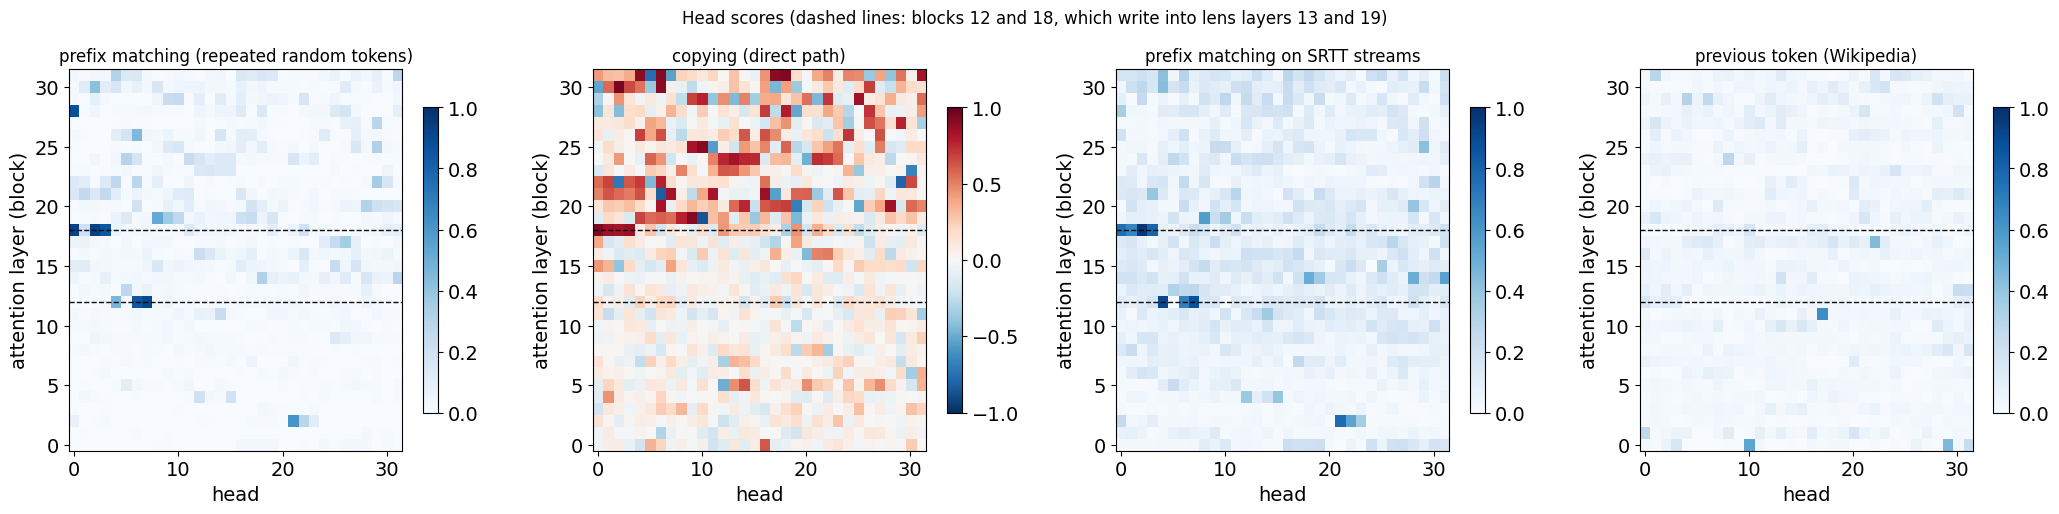

,block,head,prefix,copying,prefix on SRTT,previous token,induction (both thresholds)
rank,,,,,,,
1,18,0,0.932,0.929,0.753,0.001,True
2,18,2,0.934,0.827,0.974,0.004,True
3,18,3,0.851,0.858,0.796,0.002,True
4,19,8,0.522,0.776,0.572,0.011,True
5,30,2,0.416,0.945,0.269,0.005,True
6,19,9,0.364,0.917,0.223,0.004,True
7,26,6,0.452,0.643,0.197,0.006,False
8,31,4,0.315,0.892,0.414,0.014,True
9,20,28,0.308,0.838,0.396,0.017,True


correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = 0.78


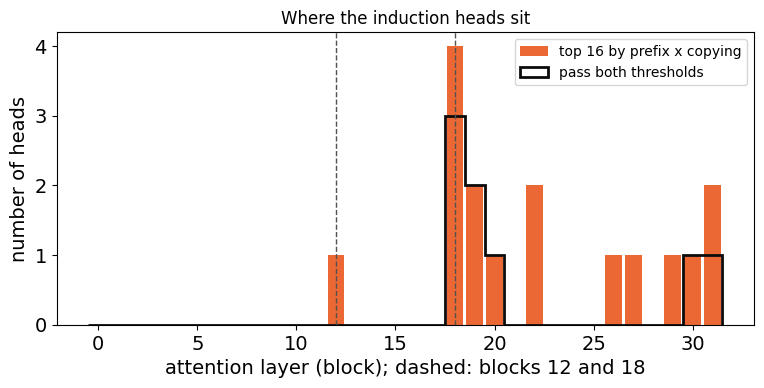

In [34]:
induction_rank_score = prefix_scores * np.clip(copy_scores, 0, None)
order = np.argsort(-induction_rank_score, axis=None)
ranked_heads = [tuple(int(v) for v in np.unravel_index(i, induction_rank_score.shape)) for i in order]
is_induction = (prefix_scores >= PREFIX_THRESHOLD) & (copy_scores >= COPY_THRESHOLD)
print(f"{int(is_induction.sum())} heads pass both thresholds (prefix >= {PREFIX_THRESHOLD}, copying >= {COPY_THRESHOLD})")


def plot_head_heatmaps(panels, title):
  fig, axes = plt.subplots(1, len(panels), figsize=(5.2 * len(panels), 5.2), squeeze=False)
  for ax, (name, values, vmin, vmax, cmap) in zip(axes[0], panels):
    im = ax.imshow(values, origin='lower', aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    for block in (12, 18):  # feed lens layers 13 and 19
      if block < NUM_LAYERS:
        ax.axhline(block, color='#0b0b0b', linestyle='--', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("head")
    ax.set_ylabel("attention layer (block)")
    fig.colorbar(im, ax=ax, shrink=0.8)
  fig.suptitle(title)
  fig.tight_layout()
  plt.show()


plot_head_heatmaps([("prefix matching (repeated random tokens)", prefix_scores, 0, 1, 'Blues'),
                    ("copying (direct path)", copy_scores, -1, 1, 'RdBu_r'),
                    ("prefix matching on SRTT streams", srtt_prefix_scores, 0, 1, 'Blues'),
                    ("previous token (Wikipedia)", prev_token_scores, 0, 1, 'Blues')],
                   "Head scores (dashed lines: blocks 12 and 18, which write into lens layers 13 and 19)")

top30 = pd.DataFrame([{"rank": r + 1, "block": l, "head": h,
                       "prefix": prefix_scores[l, h], "copying": copy_scores[l, h],
                       "prefix on SRTT": srtt_prefix_scores[l, h], "previous token": prev_token_scores[l, h],
                       "induction (both thresholds)": bool(is_induction[l, h])}
                      for r, (l, h) in enumerate(ranked_heads[:30])]).set_index("rank")
display(top30.round(3))

corr = np.corrcoef(prefix_scores.ravel(), srtt_prefix_scores.ravel())[0, 1]
print(f"correlation of prefix-matching scores, random repeats vs our SRTT streams (all heads): r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
layers_top = [l for l, _ in ranked_heads[:max(K_LIST)]]
ax.hist(layers_top, bins=np.arange(NUM_LAYERS + 1) - 0.5, color='#eb6834', rwidth=0.85,
        label=f"top {max(K_LIST)} by prefix x copying")
ax.hist(np.nonzero(is_induction)[0], bins=np.arange(NUM_LAYERS + 1) - 0.5, histtype='step', color='#0b0b0b',
        linewidth=2, label="pass both thresholds")
for block in (12, 18):  # feed lens layers 13 and 19
  ax.axvline(block, color='#52514e', linestyle='--', linewidth=1)
ax.set_xlabel("attention layer (block); dashed: blocks 12 and 18")
ax.set_ylabel("number of heads")
ax.set_title("Where the induction heads sit")
ax.legend()
plt.show()

## Switch-off tools and the cached conditions (from `03_induction_heads`)

Same tools as before: a head is switched off by replacing its 128 numbers at the input of `o_proj` with their mean on
Wikipedia (mean ablation). The second cell rebuilds the head sets of the cached run (top 4, 8, 16, and 2 random
layer-matched draws of 16) exactly as they were.

In [35]:
def head_slice(h):
  return slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)


@contextmanager
def ablate_heads(model, heads, mode="mean", means=None):
  """Replaces the o_proj input slice of every (layer, head) in heads with its mean (or zero). Other heads untouched."""
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  handles = []
  for l, hs in by_layer.items():
    idx = torch.cat([torch.arange(h * HEAD_DIM, (h + 1) * HEAD_DIM) for h in hs])
    replacement = None if mode == "zero" else means[l][idx]

    def pre_hook(module, args, idx=idx, replacement=replacement):
      x = args[0].clone()
      idx_d = idx.to(x.device)
      x[..., idx_d] = 0 if replacement is None else replacement.to(device=x.device, dtype=x.dtype)
      return (x,) + tuple(args[1:])

    handles.append(model.model.layers[l].self_attn.o_proj.register_forward_pre_hook(pre_hook))
  try:
    yield
  finally:
    for handle in handles:
      handle.remove()


def compute_head_means():
  """Mean o_proj input per layer over Wikipedia text (train split; BOS position excluded)."""
  device = get_device()
  tokens = load_lens_training_tokens(tokenizer, MEAN_ABLATION_SEQS, TUNED_LENS_SEQ_LEN, "train")
  sums = torch.zeros(NUM_LAYERS, NUM_HEADS * HEAD_DIM, dtype=torch.float64)
  count = 0
  with torch.no_grad(), capture_heads(model, attention=False) as store:
    for start in range(0, len(tokens), WIKI_BATCH):
      model(input_ids=tokens[start:start + WIKI_BATCH].to(device), use_cache=False)
      for l in range(NUM_LAYERS):
        sums[l] += store["z"][l][:, 1:].double().sum(dim=(0, 1)).cpu()
      count += store["z"][0][:, 1:].shape[0] * store["z"][0][:, 1:].shape[1]
  return (sums / count).float().numpy()


head_means = torch.tensor(load_or_compute("head_means", compute_head_means))

# Sanity check: ablating one head changes only that head's slice of its layer's o_proj input.
check_layer, check_head = ranked_heads[0]
probe = load_lens_training_tokens(tokenizer, 1, 32, "validation").to(get_device())
with torch.no_grad():
  with capture_heads(model, attention=False) as clean:
    clean_logits = model(input_ids=probe, use_cache=False).logits.float()
  with ablate_heads(model, [(check_layer, check_head)], "mean", head_means), capture_heads(model, attention=False) as ablated:
    ablated_logits = model(input_ids=probe, use_cache=False).logits.float()
z_clean, z_abl = clean["z"][check_layer][0].float(), ablated["z"][check_layer][0].float()
inside = head_slice(check_head)
outside = torch.ones(z_clean.shape[-1], dtype=torch.bool)
outside[inside] = False
assert torch.allclose(z_clean[:, outside], z_abl[:, outside], atol=1e-3), "other heads in the layer changed"
assert torch.allclose(z_abl[:, inside], head_means[check_layer][inside].to(z_abl).expand_as(z_abl[:, inside]), atol=1e-2)
assert all(torch.allclose(clean["z"][l].float(), ablated["z"][l].float(), atol=1e-3) for l in range(check_layer)), "earlier layers changed"
print(f"[sanity] ablating layer {check_layer} head {check_head}: only its {HEAD_DIM} numbers changed in that layer; "
      f"output logits moved by up to {(clean_logits - ablated_logits).abs().max().item():.3f}")
del clean, ablated, clean_logits, ablated_logits

computed head_means in 64 s
[sanity] ablating layer 18 head 0: only its 128 numbers changed in that layer; output logits moved by up to 1.172


In [36]:
K_MAX = max(K_LIST)
induction_sets = {k: ranked_heads[:k] for k in K_LIST}
excluded = set(ranked_heads[:K_MAX]) | {(int(l), int(h)) for l, h in zip(*np.nonzero(is_induction))}


def layer_matched_random_heads(reference, seed):
  """Random non-induction heads with the same number per layer as `reference`."""
  rng = np.random.default_rng(seed)
  per_layer = defaultdict(int)
  for l, _ in reference:
    per_layer[l] += 1
  chosen = []
  for l, n in sorted(per_layer.items()):
    pool = [h for h in range(NUM_HEADS) if (l, h) not in excluded]
    assert len(pool) >= n, f"layer {l}: only {len(pool)} non-induction heads for {n} needed"
    chosen += [(l, int(h)) for h in rng.choice(pool, size=n, replace=False)]
  return chosen


def per_layer_counts(heads):
  counts = defaultdict(int)
  for l, _ in heads:
    counts[l] += 1
  return dict(counts)


conditions = {"baseline": {"heads": [], "mode": "mean", "lens": True}}
for k in K_LIST:
  conditions[f"induction_top{k}"] = {"heads": induction_sets[k], "mode": "mean", "lens": k == K_MAX}
for d in range(N_RANDOM_DRAWS):
  heads = layer_matched_random_heads(induction_sets[K_MAX], seed=d)
  assert per_layer_counts(heads) == per_layer_counts(induction_sets[K_MAX])
  conditions[f"random{K_MAX}_draw{d}"] = {"heads": heads, "mode": "mean", "lens": False}
if RUN_ZERO_ABLATION:
  conditions[f"induction_top{K_MAX}_zero"] = {"heads": induction_sets[K_MAX], "mode": "zero", "lens": False}
if RUN_PREV_TOKEN_CONDITION:
  prev_order = np.argsort(-prev_token_scores, axis=None)
  prev_heads = [tuple(int(v) for v in np.unravel_index(i, prev_token_scores.shape)) for i in prev_order[:K_MAX]]
  conditions[f"prevtoken_top{K_MAX}"] = {"heads": prev_heads, "mode": "mean", "lens": False}

print(f"[sanity] random draws match the induction set's per-layer counts: {per_layer_counts(induction_sets[K_MAX])}")
print(pd.DataFrame([{"condition": name, "heads ablated": len(c["heads"]), "mode": c["mode"],
                     "per-layer lens": c["lens"]} for name, c in conditions.items()]).set_index("condition"))

[sanity] random draws match the induction set's per-layer counts: {18: 4, 19: 2, 30: 1, 26: 1, 31: 2, 20: 1, 27: 1, 22: 2, 12: 1, 29: 1}
                 heads ablated  mode  per-layer lens
condition                                           
baseline                     0  mean            True
induction_top4               4  mean           False
induction_top8               8  mean           False
induction_top16             16  mean            True
random16_draw0              16  mean           False
random16_draw1              16  mean           False


In [37]:
def condition_tag(name, cond):
  digest = hashlib.md5(f"{sorted(cond['heads'])}|{cond['mode']}".encode()).hexdigest()[:8]
  return f"{name}_{digest}"


def condition_cache_name(name, cond, grammar):
  """Name of a condition saved by 03_induction_heads (identical to that notebook)."""
  return f"induction_heads/{lens_cache_name(grammar)}_{condition_tag(name, cond)}_{'lens' if cond['lens'] else 'final'}"


def load_cached(cache_name, prompts):
  """Loads saved per-run results without recomputing anything. Returns (results, message); results is None when the
  file is missing or was computed on different inputs (then Part 1 skips that condition instead of rerunning it)."""
  path = os.path.join(LENS_CACHE_DIR, f"{cache_name}.pkl") if LENS_CACHE_DIR else None
  if not path or not os.path.exists(path):
    return None, f"not found: {cache_name}"
  with open(path, 'rb') as f:
    saved = pickle.load(f)["logit"]
  if len(saved) < len(prompts):
    return None, f"only {len(saved)} runs saved in {cache_name}"
  for r, p in zip(saved, prompts):
    if not np.array_equal(r["input_ids"], prepare_lens_inputs(tokenizer, p)["input_ids"][0].numpy()):
      return None, f"saved on different inputs (token ids differ): {cache_name}"
  return saved[:len(prompts)], "ok"

## Settings for the new steps

`N_RUNS_NEW` runs per grammar (the first 20 of the same streams as before), paired: every condition uses the same
streams and vocabularies, and every result is reported as the per-run difference from no switch-off.

In [38]:
N_RUNS_NEW = 20                # runs per grammar in Steps B and C (paired with the no-switch-off baseline)
TOP_N_SINGLE = 12              # the top-ranked induction heads switched off one at a time ...
EXTRA_SINGLE_HEADS = [(12, 6)] # ... plus these (block 12 head 6: high prefix matching, weak direct copying)
N_RANDOM_SINGLE = 2            # random non-induction control heads, from the layers of the top-ranked heads
ATTN_RUNS = 5                  # Step A: runs per grammar for the attention map
ATTN_QUERY_SAMPLE = 400        # Step A: query positions per run, sampled from the last LAST_N_STRUCTURED grammar words
RUN_STEP_B = False             # Step B ran in run 1 (head_specialization_run1_executed.ipynb); True to redo it
LEAVE_ONE_IN = True            # Step C: True / False, or "auto" = run only if Step B's single-head effects are tiny
TINY_EFFECT = 0.02             # "tiny": no transition moves by more than this (probability), for any single head
SIGNIFICANT_SE = 3             # a per-transition change counts as clear when |mean| > this many standard errors

SPEC_DIR = os.path.join(LENS_CACHE_DIR, "head_specialization") if LENS_CACHE_DIR else None
if SPEC_DIR:
  os.makedirs(SPEC_DIR, exist_ok=True)
new_prompts = {"AGL": agl_prompts[:N_RUNS_NEW], "SRTT": srtt_prompts[:N_RUNS_NEW]}
cached_prompts = {"AGL": agl_prompts, "SRTT": srtt_prompts}

existing = set(ranked_heads)
single_heads = list(dict.fromkeys(ranked_heads[:TOP_N_SINGLE] + [h for h in EXTRA_SINGLE_HEADS if h in existing]))
random_single = [layer_matched_random_heads([single_heads[i]], seed=100 + i)[0] for i in range(N_RANDOM_SINGLE)]
print("heads switched off one at a time:", single_heads)
print("random control heads:", random_single)

heads switched off one at a time: [(18, 0), (18, 2), (18, 3), (19, 8), (30, 2), (19, 9), (26, 6), (31, 4), (20, 28), (31, 31), (27, 29), (22, 6), (12, 6)]
random control heads: [(18, 25), (18, 12)]


## Transitions

### In plain words
Every word in the grammar phase is produced by one transition: the grammar is in some **state**, and emits a word.
- **SRTT** has 9 transitions, one per position in the repeated sequence `0 1 2 2 0 2 3 1 END`. We label them by the
  previous word and the next word (e.g. `2→0`). A transition is **ambiguous for simple copying** if the previous word
  is followed by different words at different places in the sequence: after `2` can come `2`, `0` or `3`, so "copy
  what came after `2` last time" is not enough; only `3→1` and `END→0` are unique.
- **AGL** has 11 transitions, labelled by the state before the word and the word (e.g. `q1 → 3`). Every state has 2–3
  options, so all of them are probabilistic. The table below also shows, for each previous word, which states it can
  lead into: if it is more than one, the previous word alone does not tell the model where in the grammar it is.

**The measure:** the probability of the correct next word, averaged per transition over the last 1,000 grammar words
of each run (the same window as the learning score), final output.

In [39]:
SRTT_CYCLE = []
_state = "q0"
while True:  # walk the deterministic SRTT chain once: [(state, symbol), ...]
  (symbol, nxt), = srtt_transitions[_state].items()
  SRTT_CYCLE.append((_state, symbol))
  _state = nxt
  if _state == "q0":
    break
SRTT_SUCCESSORS = defaultdict(set)
for k, (_, symbol) in enumerate(SRTT_CYCLE):
  SRTT_SUCCESSORS[SRTT_CYCLE[k - 1][1]].add(symbol)
SRTT_ORDER = [f"{SRTT_CYCLE[k - 1][1]}→{symbol}" for k, (_, symbol) in enumerate(SRTT_CYCLE)]
SRTT_AMBIGUOUS = {f"{SRTT_CYCLE[k - 1][1]}→{symbol}": len(SRTT_SUCCESSORS[SRTT_CYCLE[k - 1][1]]) > 1
                  for k, (_, symbol) in enumerate(SRTT_CYCLE)}
AGL_ORDER = [f"{state} → {symbol}" for state in agl_transitions for symbol in agl_transitions[state]]
LEADS_INTO = defaultdict(set)  # AGL: previous word -> states it can lead into
for state, edges in agl_transitions.items():
  for symbol, nxt in edges.items():
    LEADS_INTO[symbol].add(nxt)
TRANSITION_ORDER = {"AGL": AGL_ORDER, "SRTT": SRTT_ORDER}


def transition_labels(p, grammar):
  """Label of the transition that produces each grammar-phase word t (prompt index)."""
  lb, le = p["learning_begins"], p["learning_ends"]
  states, symbols = p["structure_state_sequences"], p["placeholder_prompt"]
  if grammar == "SRTT":
    return {t: f"{symbols[t - 1]}→{symbols[t]}" for t in range(lb, le)}
  return {t: f"{states[t - lb]} → {symbols[t]}" for t in range(lb, le)}


def per_transition_probs(lens_results, prompts, grammar, last_n=LAST_N_STRUCTURED):
  """(runs x transitions) mean probability of the correct next word, final output, last `last_n` grammar words."""
  rows = []
  for r, p in zip(lens_results, prompts):
    probs = lens_next_token_probs(r, renormalize=False)[-1]
    labels = transition_labels(p, grammar)
    acc = defaultdict(list)
    for t in range(p["learning_ends"] - last_n, p["learning_ends"]):
      acc[labels[t]].append(probs[t])
    rows.append({k: np.mean(v) for k, v in acc.items()})
  return pd.DataFrame(rows)[[k for k in TRANSITION_ORDER[grammar] if k in rows[0]]]


def paired_change(condition_df, baseline_df):
  """Per-run difference from baseline, per transition: mean and standard error (negative = worse)."""
  diff = condition_df.values - baseline_df.values
  n = diff.shape[0]
  return (pd.Series(diff.mean(0), index=baseline_df.columns),
          pd.Series(diff.std(0, ddof=1) / np.sqrt(n) if n > 1 else np.zeros(diff.shape[1]), index=baseline_df.columns))


def specialization_index(mean_change):
  """How concentrated the damage is across transitions: 0 = spread evenly, 1 = all on one transition.
  Uses drops only (negative changes); NaN when there is no drop at all."""
  drops = np.clip(-np.asarray(mean_change, dtype=float), 0, None)
  k, total = len(drops), drops.sum()
  return np.nan if total <= 0 else (drops.max() / total - 1 / k) / (1 - 1 / k)


display(pd.DataFrame({"SRTT transition": SRTT_ORDER,
                      "ambiguous for simple copying": [SRTT_AMBIGUOUS[k] for k in SRTT_ORDER],
                      "previous word can be followed by": [", ".join(sorted(SRTT_SUCCESSORS[k.split("→")[0]])) for k in SRTT_ORDER]}).set_index("SRTT transition"))
display(pd.DataFrame({"AGL: previous word": sorted(LEADS_INTO),
                      "states it can lead into": [", ".join(sorted(LEADS_INTO[w])) for w in sorted(LEADS_INTO)],
                      "identifies the state alone": [len(LEADS_INTO[w]) == 1 for w in sorted(LEADS_INTO)]}).set_index("AGL: previous word"))

,ambiguous for simple copying,previous word can be followed by
SRTT transition,,
END→0,False,0
0→1,True,"1, 2"
1→2,True,"2, END"
2→2,True,"0, 2, 3"
2→0,True,"0, 2, 3"
0→2,True,"1, 2"
2→3,True,"0, 2, 3"
3→1,False,1
1→END,True,"2, END"


,states it can lead into,identifies the state alone
AGL: previous word,,
0,"q0, q3",False
1,"q0, q1",False
2,"q0, q4",False
3,"q0, q2",False
END,q0,True


In [40]:
def new_cache_name(name, heads, grammar):
  digest = hashlib.md5(f"{sorted(heads)}|mean".encode()).hexdigest()[:8]
  return f"head_specialization/{lens_cache_name(grammar.lower())}_{name}_{digest}_n{N_RUNS_NEW}"


def run_condition(name, heads):
  """Runs (or loads) one switch-off condition on the N_RUNS_NEW streams of both grammars; per-transition table."""
  out = {}
  with ablate_heads(model, heads, "mean", head_means):
    for grammar in ("AGL", "SRTT"):
      results_ = run_lens_extraction(model, tokenizer, new_prompts[grammar], [NUM_LAYERS], cache_name=new_cache_name(name, heads, grammar))["logit"]
      out[grammar] = per_transition_probs(results_, new_prompts[grammar], grammar)
  return out

## Part 1: the saved top-16 switch-off, transition by transition (no new runs)

### In plain words
The saved results of `03_induction_heads` (50 runs per grammar) are split by transition. For each transition: how much
lower is the probability of the correct next word with the heads switched off, compared with the same run without
switch-off? Bars = top 16 switched off (± SE across runs); triangles = top 8; dots = top 4; grey crosses = 16 random
layer-matched heads. For SRTT, orange bars are ambiguous transitions and blue bars unique ones.

If the saved `03` results are missing or were computed on different word streams, they are not reused: no switch-off,
top 16 and 16 random heads are then run fresh in this session (`N_RUNS_NEW` runs each, about 25 min) and saved.

[AGL] baseline: saved on different inputs (token ids differ): induction_heads/agl_mistral_trained_8bit_baseline_b6639803_lens
[AGL] induction_top4: not found: induction_heads/agl_mistral_trained_8bit_induction_top4_2524570f_final
[AGL] induction_top8: not found: induction_heads/agl_mistral_trained_8bit_induction_top8_16ddfc8f_final
[AGL] induction_top16: not found: induction_heads/agl_mistral_trained_8bit_induction_top16_5204773d_lens
[AGL] random16_draw0: not found: induction_heads/agl_mistral_trained_8bit_random16_draw0_4209ec37_final
[AGL] random16_draw1: not found: induction_heads/agl_mistral_trained_8bit_random16_draw1_9e0d48ef_final
[SRTT] baseline: saved on different inputs (token ids differ): induction_heads/srtt_mistral_trained_8bit_baseline_b6639803_lens
[SRTT] induction_top4: not found: induction_heads/srtt_mistral_trained_8bit_induction_top4_2524570f_final
[SRTT] induction_top8: not found: induction_heads/srtt_mistral_trained_8bit_induction_top8_16ddfc8f_final
[SRTT] induct

  0%|          | 0/20 [00:00<?, ?it/s]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 7.33e+00


100%|██████████| 20/20 [04:11<00:00, 12.56s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


  5%|▌         | 1/20 [00:12<03:59, 12.62s/it]

... (15 outputs left out)

  5%|▌         | 1/20 [00:12<03:57, 12.51s/it]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 6.42e+00


100%|██████████| 20/20 [04:02<00:00, 12.13s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


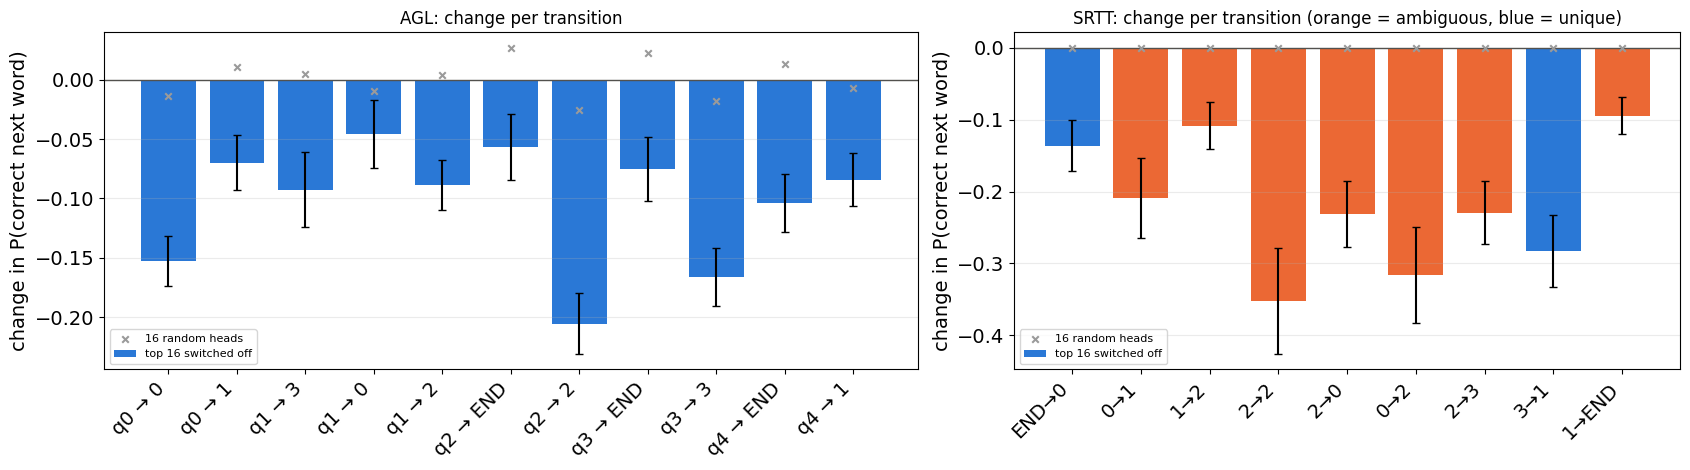

,no switch-off,induction_top16 change,induction_top16 SE,random16_draw0 change,random16_draw0 SE
q0 → 0,0.387,-0.153,0.021,-0.014,0.008
q0 → 1,0.476,-0.070,0.023,0.011,0.008
q1 → 3,0.280,-0.093,0.031,0.005,0.006
q1 → 0,0.304,-0.046,0.029,-0.009,0.006
q1 → 2,0.296,-0.089,0.021,0.004,0.006
q2 → END,0.419,-0.057,0.028,0.027,0.006
q2 → 2,0.392,-0.205,0.026,-0.025,0.007
q3 → END,0.417,-0.075,0.027,0.022,0.003
q3 → 3,0.318,-0.166,0.024,-0.018,0.003
q4 → END,0.455,-0.104,0.024,0.013,0.004


,no switch-off,induction_top16 change,induction_top16 SE,random16_draw0 change,random16_draw0 SE,ambiguous
END→0,0.997,-0.136,0.035,0.0,0.0,False
0→1,0.997,-0.209,0.056,-0.0,0.0,True
1→2,0.998,-0.109,0.033,-0.0,0.0,True
2→2,0.999,-0.352,0.074,-0.0,0.0,True
2→0,0.999,-0.232,0.046,-0.0,0.0,True
0→2,0.999,-0.316,0.067,-0.0,0.0,True
2→3,0.997,-0.230,0.044,-0.0,0.0,True
3→1,0.997,-0.283,0.050,-0.0,0.0,False
1→END,0.997,-0.094,0.026,0.0,0.0,True


SRTT, top 16 switched off: mean change on ambiguous transitions -0.220, on unique ones -0.210; difference -0.011 ± 0.035 (SE, paired over runs)


In [41]:
part1 = {}
for grammar in ("AGL", "SRTT"):
  loaded = {}
  for name, cond in conditions.items():
    results_, message = load_cached(condition_cache_name(name, cond, grammar.lower()), cached_prompts[grammar])
    print(f"[{grammar}] {name}: {message}")
    if results_ is not None:
      loaded[name] = per_transition_probs(results_, cached_prompts[grammar], grammar)
  part1[grammar] = loaded

if not all("baseline" in part1[g] and f"induction_top{K_MAX}" in part1[g] for g in part1):
  print(f"Saved 03 results are not usable for this session's streams: running no switch-off, top {K_MAX} and "
        f"{K_MAX} random heads fresh ({N_RUNS_NEW} runs each).")
  fresh = {"baseline": run_condition("baseline", []),
           f"induction_top{K_MAX}": run_condition(f"all{K_MAX}", induction_sets[K_MAX]),
           f"random{K_MAX}_draw0": run_condition(f"random{K_MAX}_draw0", conditions[f"random{K_MAX}_draw0"]["heads"])}
  part1 = {g: {name: fresh[name][g] for name in fresh} for g in ("AGL", "SRTT")}

if all("baseline" in part1[g] for g in part1):
  fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [11, 9]})
  for ax, grammar in zip(axes, ("AGL", "SRTT")):
    base = part1[grammar]["baseline"]
    x = np.arange(len(base.columns))
    if f"induction_top{K_MAX}" in part1[grammar]:
      mean, se = paired_change(part1[grammar][f"induction_top{K_MAX}"], base)
      colors = ['#eb6834' if (grammar == "SRTT" and SRTT_AMBIGUOUS[k]) else '#2a78d6' for k in base.columns]
      ax.bar(x, mean, yerr=se, color=colors, capsize=3, label=f"top {K_MAX} switched off")
    for name, marker in ((f"induction_top{K_LIST[1]}", '^'), (f"induction_top{K_LIST[0]}", 'o')):
      if name in part1[grammar]:
        ax.scatter(x, paired_change(part1[grammar][name], base)[0], marker=marker, color='#0b0b0b', s=22, zorder=3, label=name.replace("induction_", ""))
    for d in range(N_RANDOM_DRAWS):
      name = f"random{K_MAX}_draw{d}"
      if name in part1[grammar]:
        ax.scatter(x, paired_change(part1[grammar][name], base)[0], marker='x', color='#9a9a9a', s=22, zorder=3,
                   label=f"{K_MAX} random heads" if d == 0 else None)
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(base.columns, rotation=45, ha='right')
    ax.set_ylabel("change in P(correct next word)")
    ax.set_title(f"{grammar}: change per transition" + (" (orange = ambiguous, blue = unique)" if grammar == "SRTT" else ""))
    ax.grid(alpha=0.25, axis='y')
    ax.legend(fontsize=8)
  fig.tight_layout()
  plt.show()

  for grammar in ("AGL", "SRTT"):
    base = part1[grammar]["baseline"]
    table = pd.DataFrame({"no switch-off": base.mean()})
    for name in part1[grammar]:
      if name != "baseline":
        mean, se = paired_change(part1[grammar][name], base)
        table[f"{name} change"], table[f"{name} SE"] = mean, se
    if grammar == "SRTT":
      table["ambiguous"] = [SRTT_AMBIGUOUS[k] for k in table.index]
    display(table.round(3))

  # SRTT: ambiguous vs unique, paired per run
  name = f"induction_top{K_MAX}"
  if name in part1["SRTT"]:
    diff = part1["SRTT"][name] - part1["SRTT"]["baseline"]
    amb = [k for k in diff.columns if SRTT_AMBIGUOUS[k]]
    uni = [k for k in diff.columns if not SRTT_AMBIGUOUS[k]]
    contrast = diff[amb].mean(1) - diff[uni].mean(1)
    print(f"SRTT, top {K_MAX} switched off: mean change on ambiguous transitions {diff[amb].mean(1).mean():+.3f}, "
          f"on unique ones {diff[uni].mean(1).mean():+.3f}; difference {contrast.mean():+.3f} ± {contrast.std(ddof=1) / np.sqrt(len(contrast)):.3f} (SE, paired over runs)")
else:
  print("Part 1 skipped: no baseline available.")

## Step A: who looks at which transition (attention map)

### In plain words
No switching off here. For each head and each transition, we measure how much of the head's attention goes to the
**correct earlier continuation**: the earlier places in the stream where the same transition happened, i.e. where the
right answer for this transition already appeared. 0 = the head never looks there, 1 = it looks only there. Rows =
heads, columns = transitions; darker = more attention. A head that serves particular transitions shows up as a row
with a few dark cells; interchangeable heads show up as rows that look alike.

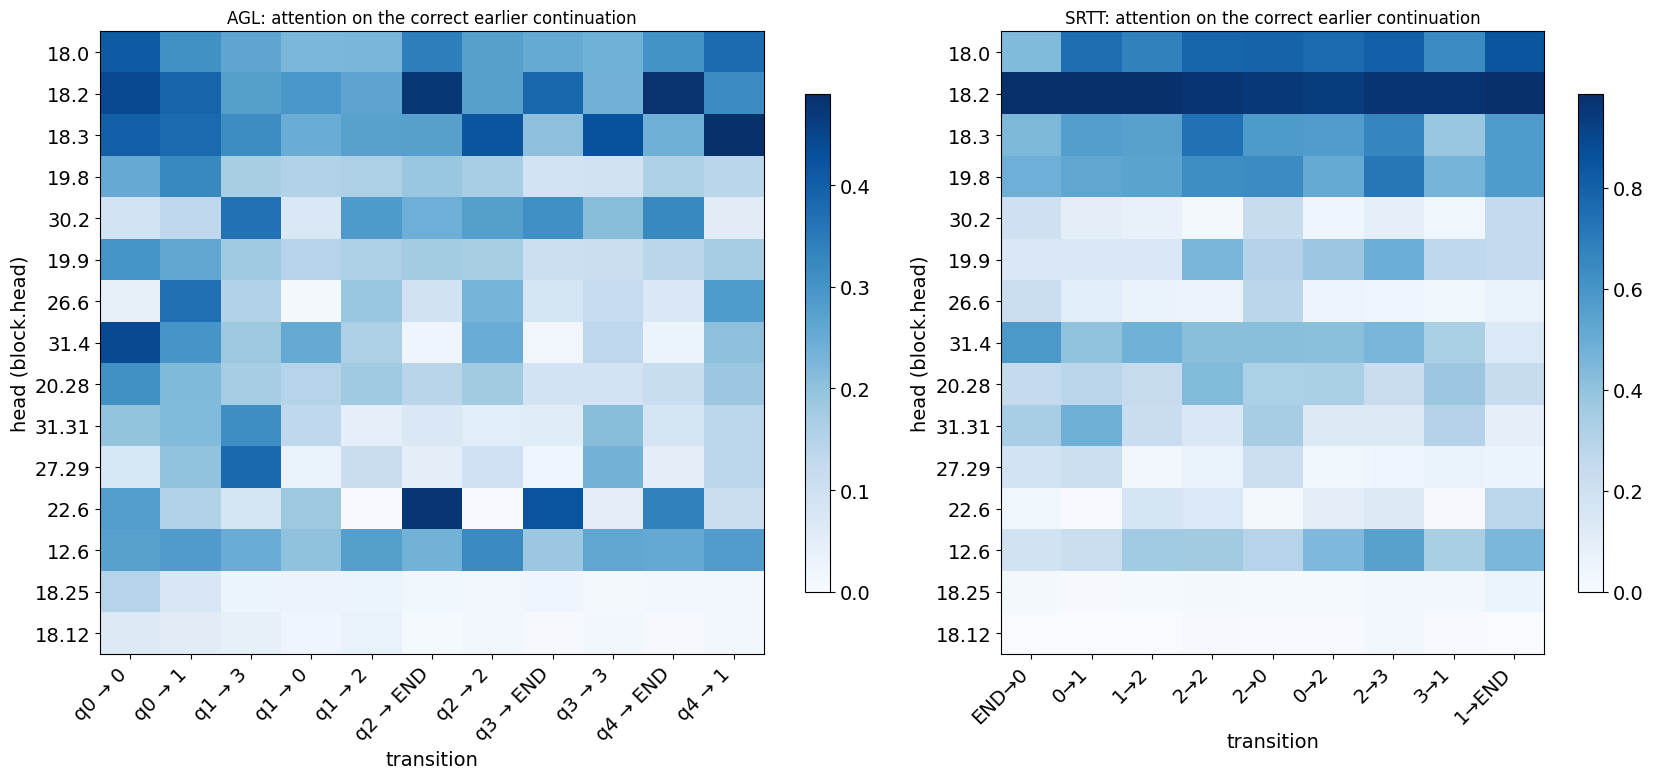

,q0 → 0,q0 → 1,q1 → 3,q1 → 0,q1 → 2,q2 → END,q2 → 2,q3 → END,q3 → 3,q4 → END,q4 → 1
18.0,0.408,0.307,0.263,0.225,0.227,0.342,0.274,0.253,0.238,0.304,0.377
18.2,0.442,0.392,0.276,0.294,0.266,0.476,0.275,0.385,0.237,0.484,0.317
18.3,0.400,0.379,0.316,0.248,0.273,0.275,0.420,0.204,0.427,0.241,0.490
19.8,0.251,0.322,0.168,0.152,0.161,0.191,0.169,0.089,0.095,0.158,0.142
30.2,0.090,0.134,0.366,0.073,0.288,0.243,0.276,0.310,0.209,0.323,0.055
19.9,0.301,0.261,0.181,0.147,0.160,0.175,0.168,0.107,0.110,0.139,0.172
26.6,0.042,0.371,0.151,0.009,0.190,0.092,0.232,0.086,0.121,0.073,0.286
31.4,0.439,0.297,0.184,0.252,0.159,0.023,0.247,0.016,0.134,0.026,0.203
20.28,0.307,0.220,0.172,0.149,0.180,0.143,0.177,0.090,0.088,0.114,0.187
31.31,0.197,0.216,0.313,0.132,0.043,0.070,0.052,0.056,0.210,0.081,0.136


,END→0,0→1,1→2,2→2,2→0,0→2,2→3,3→1,1→END
18.0,0.436,0.749,0.676,0.786,0.791,0.765,0.806,0.637,0.846
18.2,0.985,0.987,0.980,0.970,0.956,0.938,0.969,0.970,0.984
18.3,0.448,0.561,0.549,0.740,0.581,0.569,0.660,0.380,0.578
19.8,0.489,0.527,0.543,0.629,0.640,0.512,0.714,0.469,0.575
30.2,0.202,0.097,0.071,0.018,0.239,0.039,0.085,0.036,0.253
19.9,0.143,0.146,0.143,0.458,0.302,0.376,0.491,0.263,0.253
26.6,0.220,0.104,0.065,0.054,0.280,0.048,0.040,0.037,0.066
31.4,0.587,0.398,0.480,0.417,0.419,0.415,0.458,0.331,0.138
20.28,0.248,0.279,0.240,0.436,0.327,0.330,0.224,0.376,0.231
31.31,0.340,0.486,0.225,0.139,0.346,0.129,0.126,0.302,0.086


In [42]:
def attention_map(grammar, heads, n_runs=ATTN_RUNS):
  path = os.path.join(SPEC_DIR, f"attention_{lens_cache_name(grammar.lower())}_{n_runs}_{ATTN_QUERY_SAMPLE}_{hashlib.md5(repr(heads).encode()).hexdigest()[:8]}.pkl") if SPEC_DIR else None
  if path and os.path.exists(path):
    with open(path, 'rb') as f:
      print(f"loaded {grammar} attention map from {path}")
      return pickle.load(f)
  device = get_device()
  by_layer = defaultdict(list)
  for l, h in heads:
    by_layer[l].append(h)
  sums = {(head, label): [] for head in heads for label in TRANSITION_ORDER[grammar]}
  rng = np.random.default_rng(0)
  set_attention_implementation(model, "eager")
  try:
    for p in new_prompts[grammar][:n_runs]:
      ids = prepare_lens_inputs(tokenizer, p)["input_ids"]
      lb, le = p["learning_begins"], p["learning_ends"]
      labels = transition_labels(p, grammar)
      states, symbols = p["structure_state_sequences"], p["placeholder_prompt"]
      earlier = defaultdict(list)  # (state, symbol) -> prompt indices where it was emitted
      for u in range(lb, le):
        earlier[(states[u - lb], symbols[u])].append(u)
      window = np.sort(rng.choice(np.arange(le - LAST_N_STRUCTURED, le), size=min(ATTN_QUERY_SAMPLE, LAST_N_STRUCTURED), replace=False))
      mask = torch.zeros(len(window), ids.shape[1], dtype=torch.bool)
      for i, t in enumerate(window):
        us = np.array(earlier[(states[t - lb], symbols[t])])
        us = us[us < t]
        mask[i, torch.as_tensor(us + 1, dtype=torch.long)] = True  # input index of an earlier occurrence of the same transition's word
      mask = mask.to(device)
      rows = torch.as_tensor(window, device=device)
      masses = {}

      def make_hook(l):
        def hook(module, args, out):
          attn = out[1][0]  # (heads, T, T)
          for h in by_layer[l]:
            masses[(l, h)] = (attn[h][rows] * mask).sum(-1).float().cpu().numpy()
        return hook

      handles = [model.model.layers[l].self_attn.register_forward_hook(make_hook(l)) for l in by_layer]
      try:
        with torch.no_grad():
          model(input_ids=ids.to(device), use_cache=False)
      finally:
        for handle in handles:
          handle.remove()
      window_labels = [labels[t] for t in window]
      for head in heads:
        per_label = defaultdict(list)
        for label, value in zip(window_labels, masses[head]):
          per_label[label].append(value)
        for label, values in per_label.items():
          sums[(head, label)].append(np.mean(values))
  finally:
    set_attention_implementation(model, "sdpa")
  result = pd.DataFrame([[np.mean(sums[(head, label)]) if sums[(head, label)] else np.nan for label in TRANSITION_ORDER[grammar]]
                         for head in heads], index=[f"{l}.{h}" for l, h in heads], columns=TRANSITION_ORDER[grammar])
  if path:
    with open(path, 'wb') as f:
      pickle.dump(result, f)
  return result


attention_heads = single_heads + random_single
attention_maps = {grammar: attention_map(grammar, attention_heads) for grammar in ("AGL", "SRTT")}


def plot_head_transition_maps(maps, title, cmap, vmin, vmax, marks=None, center=None):
  fig, axes = plt.subplots(1, 2, figsize=(17, 0.38 * len(next(iter(maps.values()))) + 2.2), gridspec_kw={"width_ratios": [11, 9]})
  for ax, (grammar, frame) in zip(axes, maps.items()):
    values = frame.values.astype(float)
    norm = None
    if center is not None:
      from matplotlib.colors import TwoSlopeNorm
      limit = max(np.nanmax(np.abs(values)), 1e-6) if vmax is None else vmax
      norm = TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit)
      im = ax.imshow(values, aspect='auto', cmap=cmap, norm=norm, interpolation='nearest')
    else:
      im = ax.imshow(values, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_xticks(range(values.shape[1]))
    ax.set_xticklabels(frame.columns, rotation=45, ha='right')
    ax.set_yticks(range(values.shape[0]))
    ax.set_yticklabels(frame.index)
    ax.set_xlabel("transition")
    ax.set_ylabel("head (block.head)")
    ax.set_title(f"{grammar}: {title}")
    if marks is not None:
      for (i, j) in zip(*np.nonzero(marks[grammar])):
        ax.text(j, i, "*", ha='center', va='center', fontsize=10, color='#0b0b0b')
    fig.colorbar(im, ax=ax, shrink=0.8)
  fig.tight_layout()
  plt.show()


plot_head_transition_maps(attention_maps, "attention on the correct earlier continuation", 'Blues', 0, None)
for grammar in ("AGL", "SRTT"):
  display(attention_maps[grammar].round(3))

## Step B: switch off one head at a time

### In plain words
Each of the selected heads (and the 2 random control heads) is switched off on its own, and AGL and SRTT run again
(20 runs each). For every transition we compute, run by run, the change in the probability of the correct next word
compared with no switch-off, and average over runs (± SE).

**Reading the map:** red = the transition got worse, blue = better; `*` marks changes larger than 3 standard errors.
A head that serves particular transitions shows a few strong red cells; interchangeable heads show weak, even rows.

**Specialization index** (per head): how concentrated the damage is across transitions, from 0 (spread evenly) to 1
(all on one transition). It only means something when the head causes a clear drop somewhere (column
"clear drops"); the two random control heads show what values arise from noise alone.

In [43]:
if not RUN_STEP_B:
  print('Step B skipped (RUN_STEP_B = False); its results are in head_specialization_run1_executed.ipynb')
else:
  # Baseline (no switch-off): the saved one from 03 if it matches the inputs, otherwise a new 20-run baseline
  baseline = {}
  for grammar in ("AGL", "SRTT"):
    saved, message = load_cached(condition_cache_name("baseline", conditions["baseline"], grammar.lower()), new_prompts[grammar])
    print(f"[{grammar}] saved baseline: {message}")
    baseline[grammar] = per_transition_probs(saved, new_prompts[grammar], grammar) if saved is not None else None
  if any(b is None for b in baseline.values()):
    fresh = run_condition("baseline", [])
    baseline = {g: baseline[g] if baseline[g] is not None else fresh[g] for g in baseline}

  step_b_conditions = {f"{l}.{h}": [(l, h)] for l, h in single_heads}
  step_b_conditions.update({f"random {l}.{h}": [(l, h)] for l, h in random_single})
  probe_inputs = prepare_lens_inputs(tokenizer, new_prompts["AGL"][0])
  started = time.time()
  extract_lens_logprobs(model, probe_inputs, [NUM_LAYERS])
  seconds_per_run = time.time() - started
  todo = [n for n, heads in step_b_conditions.items()
          if not all(LENS_CACHE_DIR and os.path.exists(os.path.join(LENS_CACHE_DIR, new_cache_name(n, heads, g) + ".pkl")) for g in ("AGL", "SRTT"))]
  print(f"Step B: {len(step_b_conditions)} conditions, {len(todo)} to run; about "
        f"{len(todo) * 2.1 * N_RUNS_NEW * seconds_per_run / 3600:.1f} h (saved to Drive as it goes)")

  step_b = {}
  for name, heads in step_b_conditions.items():
    print(f"=== switch off {name}")
    step_b[name] = run_condition(name, heads)
  print("Step B done")

Step B skipped (RUN_STEP_B = False); its results are in head_specialization_run1_executed.ipynb


In [44]:
if not RUN_STEP_B:
  print('Step B analysis skipped (RUN_STEP_B = False)')
else:
  change_maps, clear_marks, summary_rows = {}, {}, []
  for grammar in ("AGL", "SRTT"):
    means, ses = {}, {}
    for name in step_b_conditions:
      means[name], ses[name] = paired_change(step_b[name][grammar], baseline[grammar])
    change_maps[grammar] = pd.DataFrame(means).T
    se_frame = pd.DataFrame(ses).T
    clear_marks[grammar] = (change_maps[grammar].abs() > SIGNIFICANT_SE * se_frame).values
    for name in step_b_conditions:
      drops = (change_maps[grammar].loc[name] < 0) & (change_maps[grammar].loc[name].abs() > SIGNIFICANT_SE * se_frame.loc[name])
      summary_rows.append({"grammar": grammar, "head": name,
                           "mean change (all transitions)": change_maps[grammar].loc[name].mean(),
                           "largest drop": -change_maps[grammar].loc[name].min(),
                           "at transition": change_maps[grammar].loc[name].idxmin(),
                           "clear drops": int(drops.sum()),
                           "specialization index": specialization_index(change_maps[grammar].loc[name])})

  plot_head_transition_maps(change_maps, "change in P(correct next word) when the head is switched off (* = > 3 SE)",
                            'RdBu', None, None, marks=clear_marks, center=0)
  step_b_summary = pd.DataFrame(summary_rows).set_index(["grammar", "head"])
  display(step_b_summary.round(3))

  # Does looking at a transition (Step A) go with mattering for it (Step B)?
  fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
  for ax, grammar in zip(axes, ("AGL", "SRTT")):
    att = attention_maps[grammar].loc[[n.replace("random ", "") for n in step_b_conditions]]
    att.index = list(step_b_conditions)
    x, y = att.values.ravel(), -change_maps[grammar].loc[att.index, att.columns].values.ravel()
    ok = np.isfinite(x) & np.isfinite(y)
    ax.scatter(x[ok], y[ok], s=14, color=SERIES_COLORS[grammar], alpha=0.7)
    r = np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 else np.nan
    ax.set_title(f"{grammar}: attention vs. damage per (head, transition), r = {r:.2f}")
    ax.set_xlabel("Step A: attention on the correct earlier continuation")
    ax.set_ylabel("Step B: drop when switched off")
    ax.grid(alpha=0.25)
  fig.tight_layout()
  plt.show()

  induction_names = [f"{l}.{h}" for l, h in single_heads]
  largest_single_effect = max(change_maps[g].loc[induction_names].abs().values.max() for g in change_maps)
  print(f"largest single-head change at any transition: {largest_single_effect:.3f} (tiny if below {TINY_EFFECT})")

Step B analysis skipped (RUN_STEP_B = False)


## Step C: switch off all top-16 heads except one

### In plain words
If one head alone barely matters, the others may be covering for it (redundancy). Then the opposite test is more
informative: switch off **all** top-16 heads, then give back **one** of them, and see what that single head restores,
transition by transition (compared with all 16 switched off). Blue = the head restores that transition. A head that
restores only some transitions is specialized; heads that each restore a bit everywhere are interchangeable.

By default this step runs only if the single-head changes in Step B are tiny (`LEAVE_ONE_IN = "auto"`); set
`LEAVE_ONE_IN = True` to run it anyway.

Step C runs (LEAVE_ONE_IN = True; largest single-head change in this session: n/a (Step B not run))
[AGL] saved top-16 switch-off: not found: induction_heads/agl_mistral_trained_8bit_induction_top16_5204773d_lens
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/agl_mistral_trained_8bit_all16_5204773d_n20.pkl
loaded 20 runs (logit lens) from /content/drive/MyDrive/plasticity_lens_cache/head_specialization/srtt_mistral_trained_8bit_all16_5204773d_n20.pkl
Step C: 16 conditions of about 10 min each (saved as it goes)
=== all top 16 off except 18.0


  5%|▌         | 1/20 [00:14<04:32, 14.36s/it]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 7.27e+00


100%|██████████| 20/20 [04:10<00:00, 12.52s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


  5%|▌         | 1/20 [00:12<03:56, 12.46s/it]

... (119 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

[sanity] last layer, lens vs outputs.logits: max|diff| = 0.00e+00; old double-norm lens vs outputs.logits: max|diff| = 5.93e+00


100%|██████████| 20/20 [04:01<00:00, 12.07s/it]


max |lens(last layer) - outputs.logits| over runs: 0.00e+00


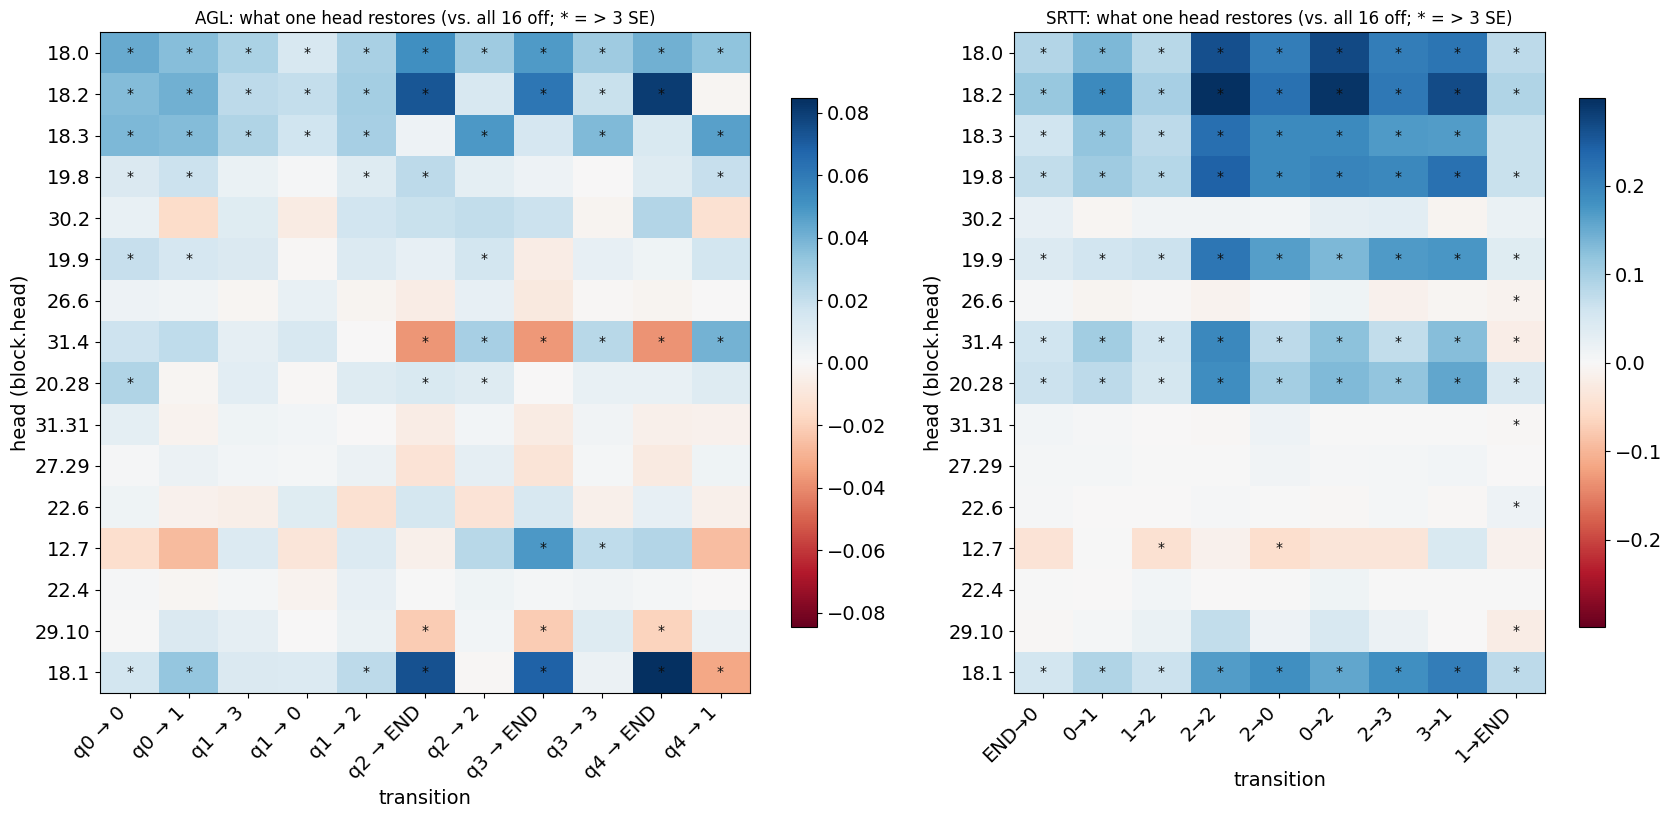

mean restored  largest restore at transition  \
grammar head kept                                                 
AGL     18.0               0.035            0.052      q2 → END   
        18.2               0.036            0.080      q4 → END   
        18.3               0.028            0.048        q2 → 2   
        19.8               0.010            0.022      q2 → END   
        30.2               0.007            0.025      q4 → END   
        19.9               0.009            0.019        q0 → 0   
        26.6              -0.000            0.007        q2 → 2   
        31.4               0.003            0.040        q4 → 1   
        20.28              0.008            0.026        q0 → 0   
        31.31             -0.000            0.009        q0 → 0   
        27.29             -0.000            0.007        q2 → 2   
        22.6               0.001            0.015      q2 → END   
        12.7               0.005            0.048      q3 → END   
        22.4               0.001            0.007        q1 → 2   
        29.10             -0.002            0.012        q0 → 1   
        18.1               0.027            0.085      q4 → END   
SRTT    18.0               0.172            0.269           0→2   
        18.2               0.198            0.299           2→2   
        18.3               0.141            0.226           2→2   
        19.8               0.153            0.242           2→2   
        30.2               0.014            0.032           2→3   
        19.9               0.117            0.215           2→2   
        26.6              -0.004            0.013           0→2   
        31.4               0.088            0.192           2→2   
        20.28              0.104            0.187           2→2   
        31.31              0.002            0.014           2→0   
        27.29              0.005            0.011           2→0   
        22.6               0.002            0.015         1→END   
        12.7              -0.021            0.045           3→1   
        22.4               0.003            0.013           0→2   
        29.10              0.017            0.073           2→2   
        18.1               0.131            0.206           3→1   

                   specialization index  
grammar head kept                        
AGL     18.0                      0.050  
        18.2                      0.124  
        18.3                      0.073  
        19.8                      0.119  
        30.2                      0.137  
        19.9                      0.102  
        26.6                      0.283  
        31.4                      0.190  
        20.28                     0.204  
        31.31                     0.367  
        27.29                     0.195  
        22.6                      0.231  
        12.7                      0.278  
        22.4                      0.259  
        29.10                     0.198  
        18.1                      0.186  
SRTT    18.0                      0.071  
        18.2                      0.063  
        18.3                      0.076  
        19.8                      0.073  
        30.2                      0.138  
        19.9                      0.104  
        26.6                      0.716  
        31.4                      0.139  
        20.28                     0.099  
        31.31                     0.422  
        27.29                     0.166  
        22.6                      0.536  
        12.7                      0.998  
        22.4                      0.428  
        29.10                     0.337  
        18.1                      0.071

In [45]:
largest_single_effect = globals().get("largest_single_effect")  # only set when Step B ran in this session
run_step_c = LEAVE_ONE_IN is True or (LEAVE_ONE_IN == "auto" and largest_single_effect is not None and largest_single_effect < TINY_EFFECT)
print(f"Step C {'runs' if run_step_c else 'is skipped'} (LEAVE_ONE_IN = {LEAVE_ONE_IN!r}; largest single-head change in "
      f"this session: {'n/a (Step B not run)' if largest_single_effect is None else f'{largest_single_effect:.3f}'})")
if run_step_c and "seconds_per_run" not in globals():
  probe_inputs = prepare_lens_inputs(tokenizer, new_prompts["AGL"][0])
  started = time.time()
  extract_lens_logprobs(model, probe_inputs, [NUM_LAYERS])
  seconds_per_run = time.time() - started
if run_step_c:
  top_set = induction_sets[K_MAX]
  all_off = None
  for grammar in ("AGL", "SRTT"):
    saved, message = load_cached(condition_cache_name(f"induction_top{K_MAX}", conditions[f"induction_top{K_MAX}"], grammar.lower()), new_prompts[grammar])
    print(f"[{grammar}] saved top-{K_MAX} switch-off: {message}")
    if saved is None:
      all_off = None
      break
    all_off = (all_off or {}) | {grammar: per_transition_probs(saved, new_prompts[grammar], grammar)}
  if all_off is None:
    all_off = run_condition(f"all{K_MAX}", top_set)
  print(f"Step C: {len(top_set)} conditions of about {2.1 * N_RUNS_NEW * seconds_per_run / 60:.0f} min each (saved as it goes)")
  step_c = {}
  for l, h in top_set:
    print(f"=== all top {K_MAX} off except {l}.{h}")
    step_c[f"{l}.{h}"] = run_condition(f"allbut_{l}_{h}", [x for x in top_set if x != (l, h)])
  restore_maps, restore_marks, rows = {}, {}, []
  for grammar in ("AGL", "SRTT"):
    means, ses = {}, {}
    for name in step_c:
      means[name], ses[name] = paired_change(step_c[name][grammar], all_off[grammar])
    restore_maps[grammar] = pd.DataFrame(means).T
    se_frame = pd.DataFrame(ses).T
    restore_marks[grammar] = (restore_maps[grammar].abs() > SIGNIFICANT_SE * se_frame).values
    for name in step_c:
      rows.append({"grammar": grammar, "head kept": name, "mean restored": restore_maps[grammar].loc[name].mean(),
                   "largest restore": restore_maps[grammar].loc[name].max(),
                   "at transition": restore_maps[grammar].loc[name].idxmax(),
                   "specialization index": specialization_index(-restore_maps[grammar].loc[name])})
  plot_head_transition_maps(restore_maps, f"what one head restores (vs. all {K_MAX} off; * = > 3 SE)", 'RdBu', None, None,
                            marks=restore_marks, center=0)
  display(pd.DataFrame(rows).set_index(["grammar", "head kept"]).round(3))

## How to interpret the results

- **Part 1, SRTT ambiguous transitions drop more than unique ones** → the switched-off heads matter most where simple
  copying is not enough; the unique transitions are covered by other routes.
- **Step B, a few strong red cells per head, different cells for different heads, specialization index well above
  the random control heads** → the heads specialize in particular transitions (the hypothesis).
- **Step B, weak and even rows** → the heads are largely interchangeable for single switch-offs; then Step C decides:
  - **Step C, each head restores only some transitions** → specialized but redundant (several heads cover each
    transition);
  - **Step C, each head restores a little everywhere** → one shared mechanism spread over many heads.
- **Step A and Step B agree** (heads that look at a transition also matter for it) → attention is a good guide to a
  head's role; if not, the heads' effects run through other paths (e.g. later heads that read their output).